# Прогнозирование стоимости недвижимости
### Проект по машинному обучению · регрессия · объявления о жилье (Турция, сентябрь 2018 – февраль 2019)

**Выполнил:** см. ячейку конфигурации ниже  ·  **Данные:** `real_estate_data.csv` (403 487 объявлений)  ·  **Целевая переменная:** `price`

---
## Содержание
1. **Этап 1. Исследование данных (EDA)** — структура, статистики, визуализация, пропуски, дубликаты, аномалии, гипотезы
2. **Этап 2. Предобработка** — пропуски, выбросы, кодирование, признаки, масштабирование, разбиение train/val/test
3. **Этап 3. Модели регрессии** — 4 модели разной природы, подбор гиперпараметров, метрики, сравнение, важность признаков
4. **Этап 4. Финальная модель** — обоснование выбора, сохранение артефактов
5. **Тестирование на 20 объектах** (`test_real_estate_samples.csv`) — прогноз, метрики MAE / RMSE / R² вручную и через sklearn, анализ
6. **Итоговые выводы**

## 0. Настройка окружения

In [10]:
import warnings, json, time, re, sys, platform
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
import sklearn, joblib
from IPython.display import display, Markdown, HTML

warnings.filterwarnings("ignore")

# ---------- конфигурация проекта ----------
STUDENT_FIO   = "Гумеров Алик Альбертович"   
STUDENT_GROUP = "23П-2"                 
RANDOM_STATE  = 42                      

# ---------- оформление графиков ----------
COLORS = {"Продажа": "#2E5EAA", "Аренда": "#E07A5F", "Тип 3": "#3D9970"}
ACCENT, GREY = "#F2B134", "#8D99AE"
sns.set_theme(style="whitegrid", context="notebook", font_scale=1.0)
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold", "axes.titlesize": 13,
                     "axes.labelsize": 11, "axes.spines.top": False, "axes.spines.right": False})
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_columns = 40
pd.options.display.width = 160

def fmt_money(x, _=None):
    return f"{x/1e6:.1f} млн" if abs(x) >= 1e6 else (f"{x/1e3:.0f} тыс" if abs(x) >= 1e4 else f"{x:.0f}")

SEG = {1: "Продажа", 2: "Аренда", 3: "Тип 3"}
print(f"Python {platform.python_version()} | pandas {pd.__version__} | numpy {np.__version__} | scikit-learn {sklearn.__version__}")

Python 3.13.5 | pandas 2.2.3 | numpy 2.0.2 | scikit-learn 1.6.0


**Модуль `real_estate_features.py`.** Весь код разбора признаков и предобработки вынесен в отдельный модуль (структура кода: данные → признаки → модели). Это нужно, чтобы сохранённую модель можно было загрузить в приложении (Streamlit/FastAPI) — оно использует **ту же самую** обработку. Ячейка создаёт файл рядом с ноутбуком.

In [11]:
MODULE_SRC = r'''"""
real_estate_features.py — модуль предобработки и признаков для проекта
«Прогнозирование стоимости недвижимости».

Все классы совместимы со sklearn (fit/transform) и сохраняются вместе с моделью
через joblib, поэтому приложение (Streamlit/FastAPI) применяет ровно ту же
обработку, что и при обучении.
"""
import re
import numpy as np
import pandas as pd
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, TargetEncoder

# Приблизительные курсы к TRY на конец 2018 г. (используются только для целевой переменной)
FX_TO_TRY = {"TRY": 1.0, "USD": 5.3, "EUR": 6.1, "GBP": 6.8}

# Допустимые границы площади (м²): всё за пределами считается ошибкой ввода -> NaN
SIZE_MIN, SIZE_MAX = 10, 5000

_AGE_MAP = {"6-10 arası": 8, "11-15 arası": 13, "16-20 arası": 18, "21-25 arası": 23,
            "26-30 arası": 28, "31-35 arası": 33, "36-40 arası": 38, "40 ve üzeri": 45}
_FLOORS_MAP = {"10-20 arası": 15, "20 ve üzeri": 25}
_FLOOR_SPECIAL = {"Giriş Katı": 0, "Zemin Kat": 0, "Bahçe katı": 0, "Yüksek Giriş": 1,
                  "Bodrum Kat": -1, "Asma Kat": 0.5}
_TOP_FLOOR_KINDS = {"Çatı Katı", "En Üst Kat", "Teras Kat"}

NUM_COLS = ["log_size", "rooms_total", "rooms_extra", "building_age", "total_floors",
            "floor_num", "floor_ratio", "month_idx", "size_missing", "age_missing", "floor_missing"]
OHE_COLS = ["sub_type", "heating_type", "floor_kind", "listing_type"]
TE_COLS = ["loc_city", "loc_district", "loc_neigh"]

RAW_REQUIRED = ["sub_type", "start_date", "listing_type", "building_age", "total_floor_count",
                "floor_no", "room_count", "size", "address", "heating_type"]


def _to_num(value, mapping=None):
    if pd.isna(value):
        return np.nan
    s = str(value).strip()
    if mapping and s in mapping:
        return mapping[s]
    try:
        return float(s)
    except ValueError:
        return np.nan


def _parse_rooms(value):
    """'3+1' -> (3, 1); '+' или NaN -> (nan, nan)."""
    if pd.isna(value):
        return np.nan, np.nan
    m = re.fullmatch(r"\s*(\d+)\s*\+\s*(\d+)\s*", str(value))
    if not m:
        return np.nan, np.nan
    return float(m.group(1)), float(m.group(2))


def _parse_floor(value, total_floors):
    """Возвращает (floor_num, floor_kind)."""
    if pd.isna(value):
        return np.nan, "unknown"
    s = str(value).strip()
    if s in _FLOOR_SPECIAL:
        return float(_FLOOR_SPECIAL[s]), s
    if s in _TOP_FLOOR_KINDS:
        return (float(total_floors) if pd.notna(total_floors) else np.nan), s
    m = re.fullmatch(r"Kot (\d+)", s)
    if m:                                    # подземные уровни: Kot 1 = -1 и т.д.
        return -float(m.group(1)), "Kot"
    if s == "20 ve üzeri":
        return 20.0, "numeric"
    try:
        return float(s), "numeric"
    except ValueError:                       # Müstakil, Komple и т.п.
        return np.nan, s


class FeatureBuilder(BaseEstimator, TransformerMixin):
    """Без состояния: превращает «сырую» таблицу объявлений в таблицу признаков."""

    def fit(self, X, y=None):
        self.is_fitted_ = True
        return self

    def transform(self, X):
        X = pd.DataFrame(X).copy()
        out = pd.DataFrame(index=X.index)

        size = pd.to_numeric(X["size"], errors="coerce")
        out["size"] = size.where((size >= SIZE_MIN) & (size <= SIZE_MAX))
        out["size_missing"] = out["size"].isna().astype(int)

        rooms = X["room_count"].map(_parse_rooms)
        out["rooms_main"] = rooms.map(lambda t: t[0])
        out["rooms_extra"] = rooms.map(lambda t: t[1])
        out["rooms_total"] = out["rooms_main"] + out["rooms_extra"]

        out["building_age"] = X["building_age"].map(lambda v: _to_num(v, _AGE_MAP))
        out["age_missing"] = out["building_age"].isna().astype(int)
        out["total_floors"] = X["total_floor_count"].map(lambda v: _to_num(v, _FLOORS_MAP))

        fl = [_parse_floor(v, t) for v, t in zip(X["floor_no"], out["total_floors"])]
        out["floor_num"] = [f[0] for f in fl]
        out["floor_kind"] = [f[1] for f in fl]
        out["floor_missing"] = out["floor_num"].isna().astype(int)

        dates = pd.to_datetime(X["start_date"], format="%m/%d/%y", errors="coerce")
        out["month_idx"] = (dates.dt.year - 2018) * 12 + dates.dt.month - 9   # сент. 2018 = 0

        parts = X["address"].fillna("").str.split("/", expand=True).reindex(columns=[0, 1, 2])
        city = parts[0].fillna("NA").str.strip()
        district = parts[1].fillna("NA").str.strip()
        neigh = parts[2].fillna("NA").str.strip()
        lt = X["listing_type"].astype(int).astype(str)
        out["listing_type"] = lt
        out["city"] = city
        # ключи содержат тип объявления: цены продажи и аренды несопоставимы
        out["loc_city"] = city + "|" + lt
        out["loc_district"] = city + "/" + district + "|" + lt
        out["loc_neigh"] = city + "/" + district + "/" + neigh + "|" + lt

        out["sub_type"] = X["sub_type"].fillna("unknown").astype(str)
        out["heating_type"] = X["heating_type"].fillna("unknown").astype(str)
        return out


class GroupMedianImputer(BaseEstimator, TransformerMixin):
    """Заполняет пропуски медианой по группе (fit — только на train), затем глобальной медианой."""

    def __init__(self, rules=None):
        self.rules = rules

    def fit(self, X, y=None):
        self.rules_ = self.rules or {}
        self.group_medians_, self.global_medians_ = {}, {}
        for col, groups in self.rules_.items():
            self.global_medians_[col] = X[col].median()
            self.group_medians_[col] = X.groupby(groups, dropna=False)[col].median().rename("_med").reset_index()
        return self

    def transform(self, X):
        X = X.copy()
        for col, groups in self.rules_.items():
            miss = X[col].isna()
            if miss.any():
                merged = X.loc[miss, groups].merge(self.group_medians_[col], on=groups, how="left")
                X.loc[miss, col] = merged["_med"].values
            X[col] = X[col].fillna(self.global_medians_[col])
        return X


class DerivedFeatures(BaseEstimator, TransformerMixin):
    """Производные признаки после импутации (без использования цены!)."""

    def fit(self, X, y=None):
        self.is_fitted_ = True
        return self

    def transform(self, X):
        X = X.copy()
        X["log_size"] = np.log(X["size"])
        X["floor_ratio"] = (X["floor_num"] / X["total_floors"].clip(lower=1)).clip(-1, 1)
        return X


IMPUTE_RULES = {
    "size": ["sub_type", "rooms_total", "listing_type"],
    "rooms_total": ["sub_type"],
    "rooms_extra": ["sub_type"],
    "building_age": ["city", "sub_type"],
    "total_floors": ["sub_type"],
    "floor_num": ["sub_type", "floor_kind"],
    "month_idx": ["listing_type"],
}


def make_column_transformer(scale: bool):
    """scale=True — для линейных моделей (StandardScaler), False — для деревьев."""
    num_step = StandardScaler() if scale else "passthrough"
    ct = ColumnTransformer(
        [("num", num_step, NUM_COLS),
         ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False, min_frequency=30), OHE_COLS),
         ("te", TargetEncoder(target_type="continuous", smooth="auto", cv=5, random_state=42), TE_COLS)],
        verbose_feature_names_out=False)
    ct.set_output(transform="pandas")
    return ct


def make_preprocessor(scale: bool):
    """Полный пайплайн предобработки: сырой DataFrame -> числовая матрица."""
    from sklearn.pipeline import Pipeline
    return Pipeline([
        ("features", FeatureBuilder()),
        ("impute", GroupMedianImputer(IMPUTE_RULES)),
        ("derived", DerivedFeatures()),
        ("encode", make_column_transformer(scale)),
    ])
'''
Path('real_estate_features.py').write_text(MODULE_SRC, encoding='utf-8')
print('Создан модуль real_estate_features.py')

from real_estate_features import (FeatureBuilder, make_preprocessor, FX_TO_TRY, RAW_REQUIRED,
                                  NUM_COLS, IMPUTE_RULES, GroupMedianImputer, DerivedFeatures)

Создан модуль real_estate_features.py


---
# Этап 1. Исследование данных (EDA)
## 1.1 Знакомство с данными

In [12]:
RAW_PATH = Path("real_estate_data.csv")
if not RAW_PATH.exists():                       # данные могут лежать в архиве
    import zipfile
    zipfile.ZipFile("real_estate_data_csv.zip").extract("real_estate_data.csv")

STR_COLS = {"floor_no": str, "heating_type": str, "building_age": str,
            "total_floor_count": str, "room_count": str}          # смешанные типы читаем как текст
df_raw = pd.read_csv(RAW_PATH, dtype=STR_COLS)

print(f"Размерность: {df_raw.shape[0]:,} строк × {df_raw.shape[1]} столбцов")
print(f"Объём в памяти: {df_raw.memory_usage(deep=True).sum()/1024**2:.0f} МБ")

Размерность: 403,487 строк × 17 столбцов
Объём в памяти: 281 МБ


**Источник и описание данных.** Набор — выгрузка объявлений о продаже и аренде жилой недвижимости в Турции (адреса вида `Город/Район/Квартал`), период публикации — сентябрь 2018 – февраль 2019. Цена указана в валюте объявления (`price_currency`). **Целевая переменная — `price`.**

| Столбец | Смысл | Тип |
|---|---|---|
| `id` | идентификатор объявления | число |
| `type` | тип недвижимости (везде `Konut` — жильё) | категория |
| `sub_type` | подтип: квартира (Daire), вилла, отдельный дом (Müstakil Ev), резиденция, дача (Yazlık), здание целиком и др. | категория |
| `start_date`, `end_date` | даты публикации и снятия объявления | дата |
| `listing_type` | 1 — продажа, 2 — аренда, 3 — особый тип (медиана цены ≈ 70 TRY — вероятно, посуточная аренда) | категория |
| `tom` | time on market — сколько дней висело объявление | число |
| `building_age` | возраст здания (число или диапазон «6-10 arası») | категория |
| `total_floor_count`, `floor_no` | этажность здания; этаж объекта (число или «Müstakil», «Bahçe katı» …) | категория |
| `room_count` | комнаты в формате «спальни+гостиные» (например, `3+1`) | категория |
| `size` | площадь, м² | число |
| `address` | `Город/Район/Квартал` | текст |
| `furnished` | меблировка — **столбец полностью пуст** | — |
| `heating_type` | тип отопления | категория |
| `price`, `price_currency` | **цена** и валюта (TRY, USD, EUR, GBP) | число / категория |

In [13]:
display(pd.DataFrame({"Тип": df_raw.dtypes.astype(str),
                      "Непустых": df_raw.notna().sum(),
                      "Уникальных": df_raw.nunique()}))

,Тип,Непустых,Уникальных
id,int64,403487,403487
type,object,403487,1
sub_type,object,403487,12
start_date,object,403487,181
end_date,object,266298,181
listing_type,int64,403487,3
tom,int64,403487,181
building_age,object,376097,14
total_floor_count,object,375466,12
floor_no,object,368191,35


In [14]:
print("▶ Первые 5 строк"); display(df_raw.head())
print("▶ Последние 5 строк"); display(df_raw.tail())
print("▶ Случайная строка (random_state=42)"); display(df_raw.sample(1, random_state=RANDOM_STATE).T)

▶ Первые 5 строк


,id,type,sub_type,start_date,end_date,listing_type,tom,building_age,total_floor_count,floor_no,room_count,size,address,furnished,heating_type,price,price_currency
0,1,Konut,Rezidans,12/10/18,1/9/19,2,30,0,20 ve üzeri,2,2+1,90.00,İstanbul/Kartal/Kordonboyu,NaN,Fancoil,"3,500.00",TRY
1,2,Konut,Daire,2/13/19,NaN,1,14,0,20 ve üzeri,20 ve üzeri,1+0,43.00,İstanbul/Kartal/Kordonboyu,NaN,Fancoil,"490,000.00",TRY
2,3,Konut,Daire,10/9/18,11/8/18,1,30,0,1,Yüksek Giriş,2+1,NaN,Tekirdağ/Çorlu/Reşadiye,NaN,Fancoil,"155,000.00",TRY
3,4,Konut,Rezidans,9/10/18,10/10/18,1,30,3,20 ve üzeri,20 ve üzeri,6+1,450.00,İstanbul/Beşiktaş/Levent,NaN,Fancoil,"32,500,000.00",TRY
4,5,Konut,Rezidans,12/10/18,1/9/19,1,30,0,20 ve üzeri,2,2+1,90.00,İstanbul/Kartal/Kordonboyu,NaN,Fancoil,"1,450,000.00",TRY


▶ Последние 5 строк


,id,type,sub_type,start_date,end_date,listing_type,tom,building_age,total_floor_count,floor_no,room_count,size,address,furnished,heating_type,price,price_currency
403482,403483,Konut,Daire,9/18/18,NaN,2,162,NaN,NaN,NaN,+,NaN,İstanbul/Sultanbeyli/Adil,NaN,NaN,"1,500.00",TRY
403483,403484,Konut,Daire,10/11/18,NaN,1,139,NaN,NaN,NaN,2+1,NaN,Sakarya/Adapazarı/Cumhuriyet,NaN,NaN,"120,000.00",TRY
403484,403485,Konut,Daire,11/22/18,NaN,1,97,NaN,NaN,NaN,1+1,NaN,Antalya/Alanya/Saray,NaN,NaN,"48,000.00",EUR
403485,403486,Konut,Daire,2/21/19,NaN,2,6,NaN,NaN,NaN,2+1,2.00,Aydın/Kuşadası/Türkmen,NaN,NaN,900.00,TRY
403486,403487,Konut,Daire,1/15/19,1/18/19,1,3,NaN,NaN,NaN,3+1,140.00,Kayseri/Melikgazi/Alpaslan,NaN,NaN,"210,000.00",TRY


▶ Случайная строка (random_state=42)


,60623
id,60624
type,Konut
sub_type,Daire
start_date,11/20/18
end_date,2/23/19
listing_type,1
tom,95
building_age,6-10 arası
total_floor_count,5
floor_no,1


## 1.2 Описательная статистика

In [15]:
# Валюты приводим к лирам (курсы на конец 2018 г. — приблизительные; нужны только для цены)
df_raw["price_try"] = df_raw["price"] * df_raw["price_currency"].map(FX_TO_TRY)

# Разбираем сырые строки в числовые признаки (FeatureBuilder не имеет состояния → утечки быть не может)
eda = FeatureBuilder().transform(df_raw)
eda["price_try"] = df_raw["price_try"]
eda["tom"] = df_raw["tom"]
eda["segment"] = df_raw["listing_type"].map(SEG)

print("Валюты объявлений:"); display(df_raw["price_currency"].value_counts(dropna=False).to_frame("объявлений"))
print("\nТипы объявлений (listing_type):")
display(df_raw.groupby("listing_type")["price_try"].agg(["count", "median", "mean"]).rename(
    columns={"count": "объявлений", "median": "медиана цены, TRY", "mean": "средняя цена, TRY"}))

Валюты объявлений:


,объявлений
price_currency,
TRY,400677
EUR,922
NaN,715
GBP,621
USD,552



Типы объявлений (listing_type):


,объявлений,"медиана цены, TRY","средняя цена, TRY"
listing_type,,,
1,286420,"270,000.00","508,158.47"
2,114118,"1,200.00","17,013.48"
3,2234,70.00,123.93


In [16]:
num_cols = ["price_try", "size", "rooms_total", "building_age", "total_floors", "floor_num", "tom"]
desc = eda[num_cols].describe(percentiles=[.25, .5, .75]).T
desc["асимметрия"] = eda[num_cols].skew()
desc.columns = ["кол-во", "среднее", "std", "min", "Q1", "медиана", "Q3", "max", "асимметрия"]
display(desc)

,кол-во,среднее,std,min,Q1,медиана,Q3,max,асимметрия
price_try,"402,772.00","366,183.78","4,843,235.37",-250.00,"2,500.00","200,000.00","345,000.00","2,000,000,000.00",302.28
size,"256,871.00",126.81,110.49,10.00,85.00,110.00,140.00,"4,999.00",17.37
rooms_total,"400,589.00",3.69,1.14,0.00,3.00,4.00,4.00,20.00,1.39
building_age,"376,097.00",6.90,8.72,0.00,0.00,3.00,13.00,45.00,1.39
total_floors,"375,466.00",5.90,4.43,1.00,3.00,4.00,6.00,25.00,2.16
floor_num,"343,902.00",2.91,3.22,-4.00,1.00,2.00,4.00,25.00,1.85
tom,"403,487.00",57.02,44.36,0.00,29.00,40.00,90.00,180.00,0.84


> **Наблюдения.** Средние сильно отличаются от медиан, а `max` на порядки больше `Q3` (цена до 2·10⁹, площадь до 948 235 м²) — в данных есть явные ошибки ввода. Асимметрия `price_try` исчисляется сотнями: распределение с очень тяжёлым правым хвостом.

In [17]:
cat_cols = ["sub_type", "listing_type", "heating_type", "room_count", "floor_kind", "city"]
rows = []
for c in cat_cols:
    s = eda[c] if c in eda else df_raw[c]
    vc = s.value_counts()
    rows.append({"признак": c, "уникальных": s.nunique(), "самое частое": vc.index[0],
                 "доля, %": vc.iloc[0] / len(s) * 100, "топ-3": ", ".join(map(str, vc.index[:3]))})
display(pd.DataFrame(rows).set_index("признак"))
print("Уникальных кварталов (address):", df_raw["address"].nunique())

,уникальных,самое частое,"доля, %",топ-3
признак,,,,
sub_type,12,Daire,87.87,"Daire, Villa, Müstakil Ev"
listing_type,3,1,71.13,"1, 2, 3"
heating_type,17,Kombi (Doğalgaz),50.60,"Kombi (Doğalgaz), Klima, Merkezi Sistem (Isı P..."
room_count,37,3+1,39.00,"3+1, 2+1, 1+1"
floor_kind,14,numeric,65.78,"numeric, unknown, Yüksek Giriş"
city,82,İstanbul,28.93,"İstanbul, Aydın, Ankara"


Уникальных кварталов (address): 7842


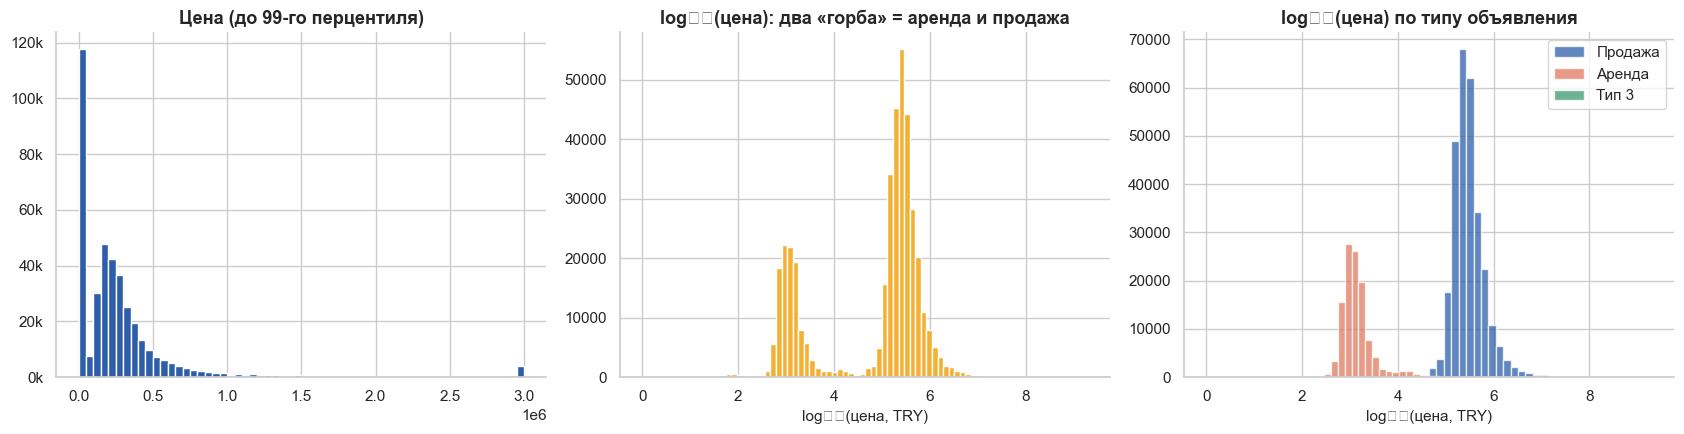

Асимметрия цены: 302.3  →  после логарифма: -0.81
Эксцесс цены:    110,592  →  после логарифма: -0.81


In [18]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
p = df_raw["price_try"].dropna(); p = p[p > 0]
axes[0].hist(p.clip(upper=p.quantile(.99)), bins=60, color=COLORS["Продажа"]); axes[0].set_title("Цена (до 99-го перцентиля)")
axes[1].hist(np.log10(p), bins=80, color=ACCENT); axes[1].set_title("log₁₀(цена): два «горба» = аренда и продажа")
axes[1].set_xlabel("log₁₀(цена, TRY)")
for s, c in COLORS.items():
    v = eda.loc[(eda.segment == s) & (eda.price_try > 0), "price_try"]
    axes[2].hist(np.log10(v), bins=60, alpha=.75, color=c, label=s)
axes[2].legend(); axes[2].set_title("log₁₀(цена) по типу объявления"); axes[2].set_xlabel("log₁₀(цена, TRY)")
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda x, _: f"{x/1e3:.0f}k"))
plt.tight_layout(); plt.show()
print(f"Асимметрия цены: {p.skew():,.1f}  →  после логарифма: {np.log(p).skew():.2f}")
print(f"Эксцесс цены:    {p.kurtosis():,.0f}  →  после логарифма: {np.log(p).kurtosis():.2f}")

> **Вывод.** Цена имеет экстремальную правостороннюю асимметрию. После логарифмирования распределение становится почти симметричным и **бимодальным**: левый горб — аренда (тысячи лир), правый — продажа (сотни тысяч). Поэтому: (1) целевую переменную будем логарифмировать, (2) тип объявления — один из главных признаков.

## 1.3 Визуальный анализ

In [19]:
def log_iqr_mask(price, seg, k=3.0):
    """True для строк, цена которых не выходит за k·IQR (в лог-шкале) внутри своего типа объявления."""
    lp = np.log(price)
    q1 = lp.groupby(seg).transform(lambda s: s.quantile(.25))
    q3 = lp.groupby(seg).transform(lambda s: s.quantile(.75))
    return (lp >= q1 - k * (q3 - q1)) & (lp <= q3 + k * (q3 - q1))

# Для графиков убираем явные выбросы цены (в моделировании это делается в Этапе 2)
ok = (eda.price_try > 0) & eda.price_try.notna()
ok &= log_iqr_mask(eda.price_try.where(ok, 1), eda.segment)
ev = eda[ok]
print(f"Для визуализации используется {len(ev):,} из {len(eda):,} строк")

Для визуализации используется 397,116 из 403,487 строк


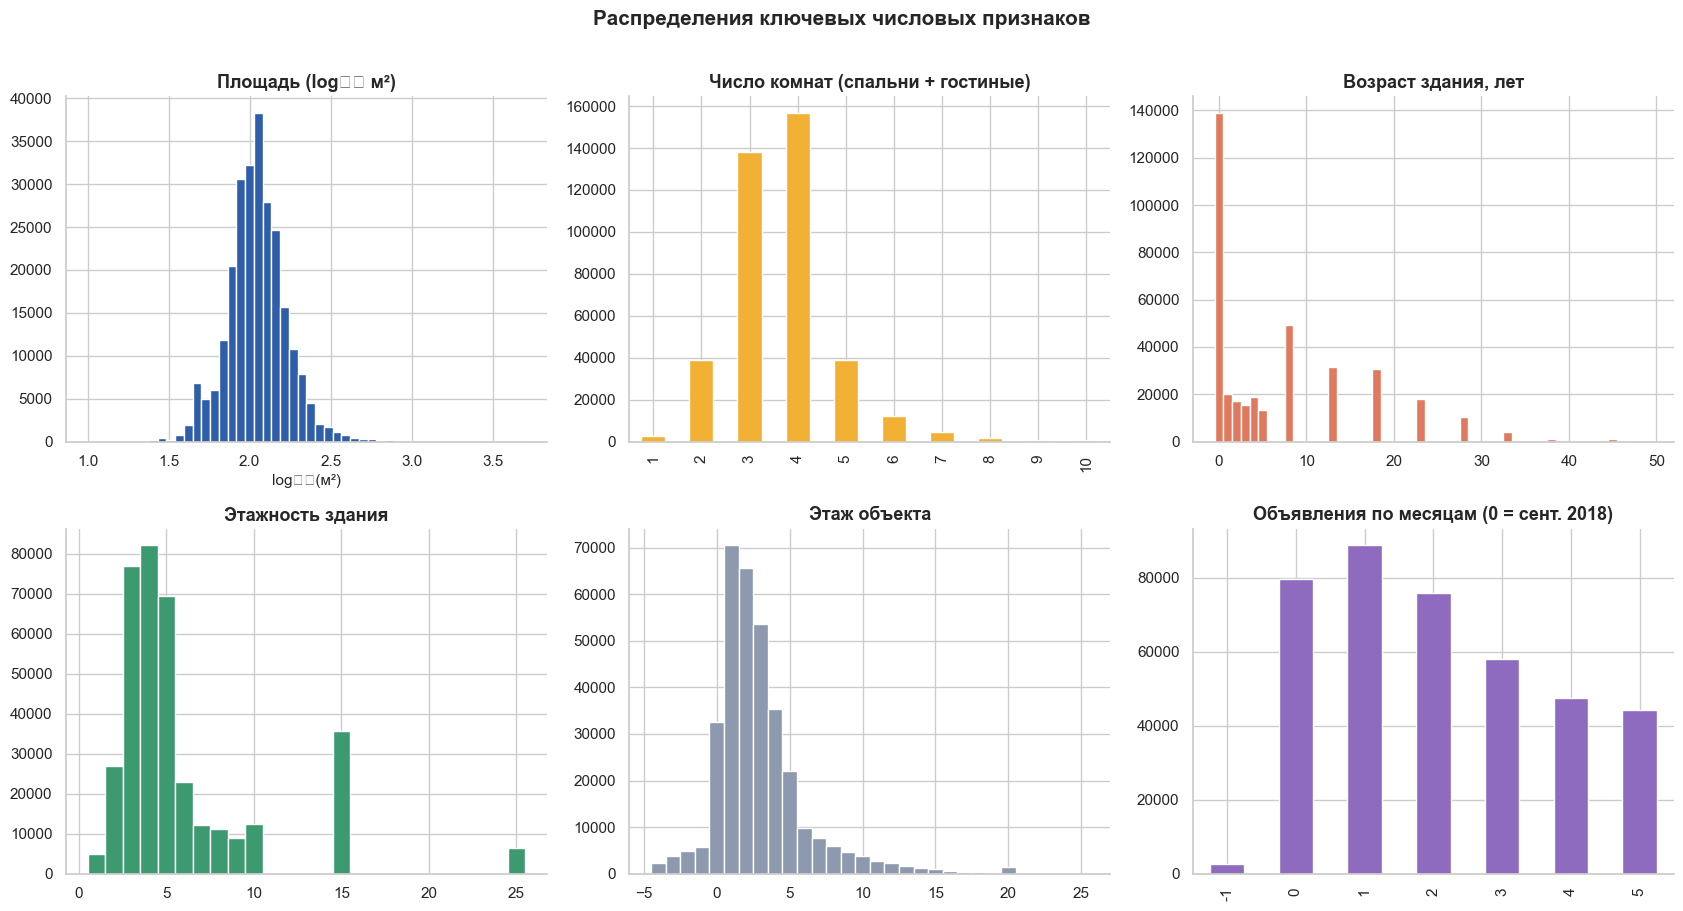

In [20]:
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
d = ev[ev["size"].notna()]
axes[0, 0].hist(np.log10(d["size"]), bins=50, color=COLORS["Продажа"]); axes[0, 0].set_title("Площадь (log₁₀ м²)"); axes[0, 0].set_xlabel("log₁₀(м²)")
ev["rooms_total"].dropna().astype(int).clip(upper=10).value_counts().sort_index().plot.bar(ax=axes[0, 1], color=ACCENT); axes[0, 1].set_title("Число комнат (спальни + гостиные)"); axes[0, 1].set_xlabel("")
axes[0, 2].hist(ev["building_age"].dropna(), bins=np.arange(-0.5, 50, 1), color=COLORS["Аренда"]); axes[0, 2].set_title("Возраст здания, лет")
axes[1, 0].hist(ev["total_floors"].dropna(), bins=np.arange(0.5, 26, 1), color=COLORS["Тип 3"]); axes[1, 0].set_title("Этажность здания")
axes[1, 1].hist(ev["floor_num"].dropna(), bins=np.arange(-4.5, 26, 1), color=GREY); axes[1, 1].set_title("Этаж объекта")
ev["month_idx"].value_counts().sort_index().plot.bar(ax=axes[1, 2], color="#8E6BBF"); axes[1, 2].set_title("Объявления по месяцам (0 = сент. 2018)"); axes[1, 2].set_xlabel("")
plt.suptitle("Распределения ключевых числовых признаков", fontsize=15, fontweight="bold", y=1.01)
plt.tight_layout(); plt.show()

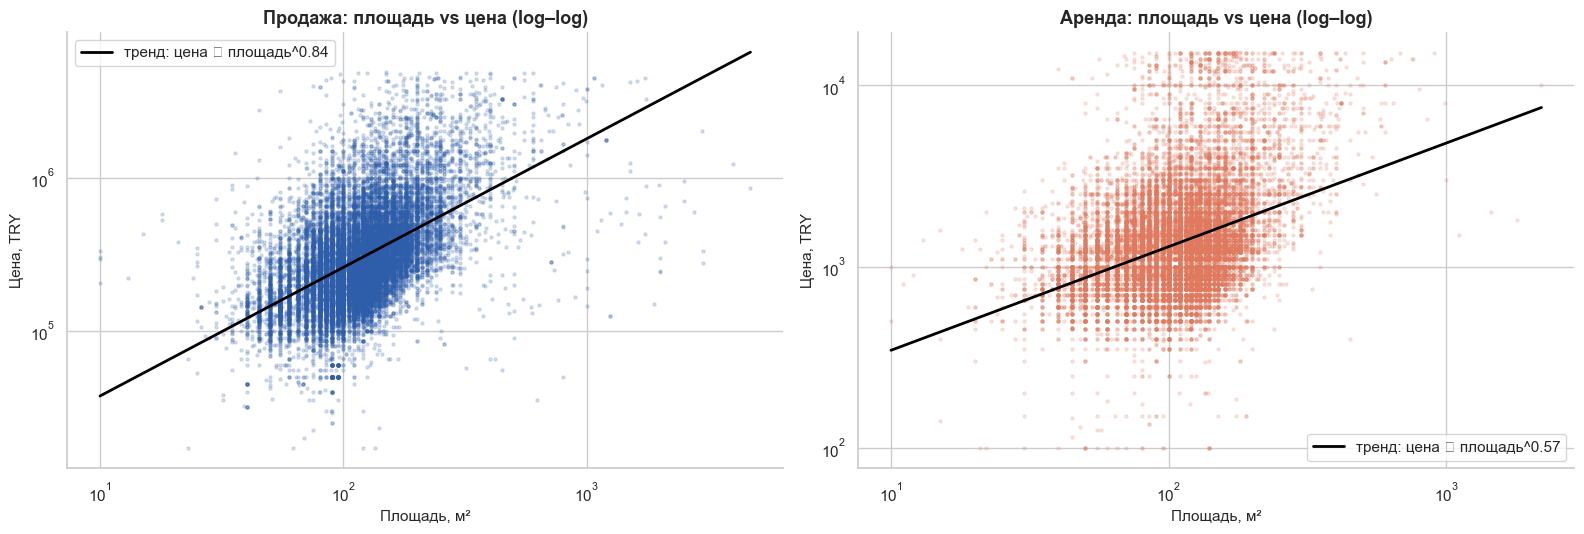

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax, seg in zip(axes, ["Продажа", "Аренда"]):
    d = ev[(ev.segment == seg) & ev["size"].notna()].sample(25000, random_state=RANDOM_STATE)
    ax.scatter(d["size"], d["price_try"], s=5, alpha=.18, color=COLORS[seg])
    k, b = np.polyfit(np.log(d["size"]), np.log(d["price_try"]), 1)
    xs = np.linspace(d["size"].min(), d["size"].max(), 200)
    ax.plot(xs, np.exp(b) * xs ** k, color="black", lw=2, label=f"тренд: цена ∝ площадь^{k:.2f}")
    ax.set_xscale("log"); ax.set_yscale("log"); ax.legend()
    ax.set_title(f"{seg}: площадь vs цена (log–log)"); ax.set_xlabel("Площадь, м²"); ax.set_ylabel("Цена, TRY")
plt.tight_layout(); plt.show()

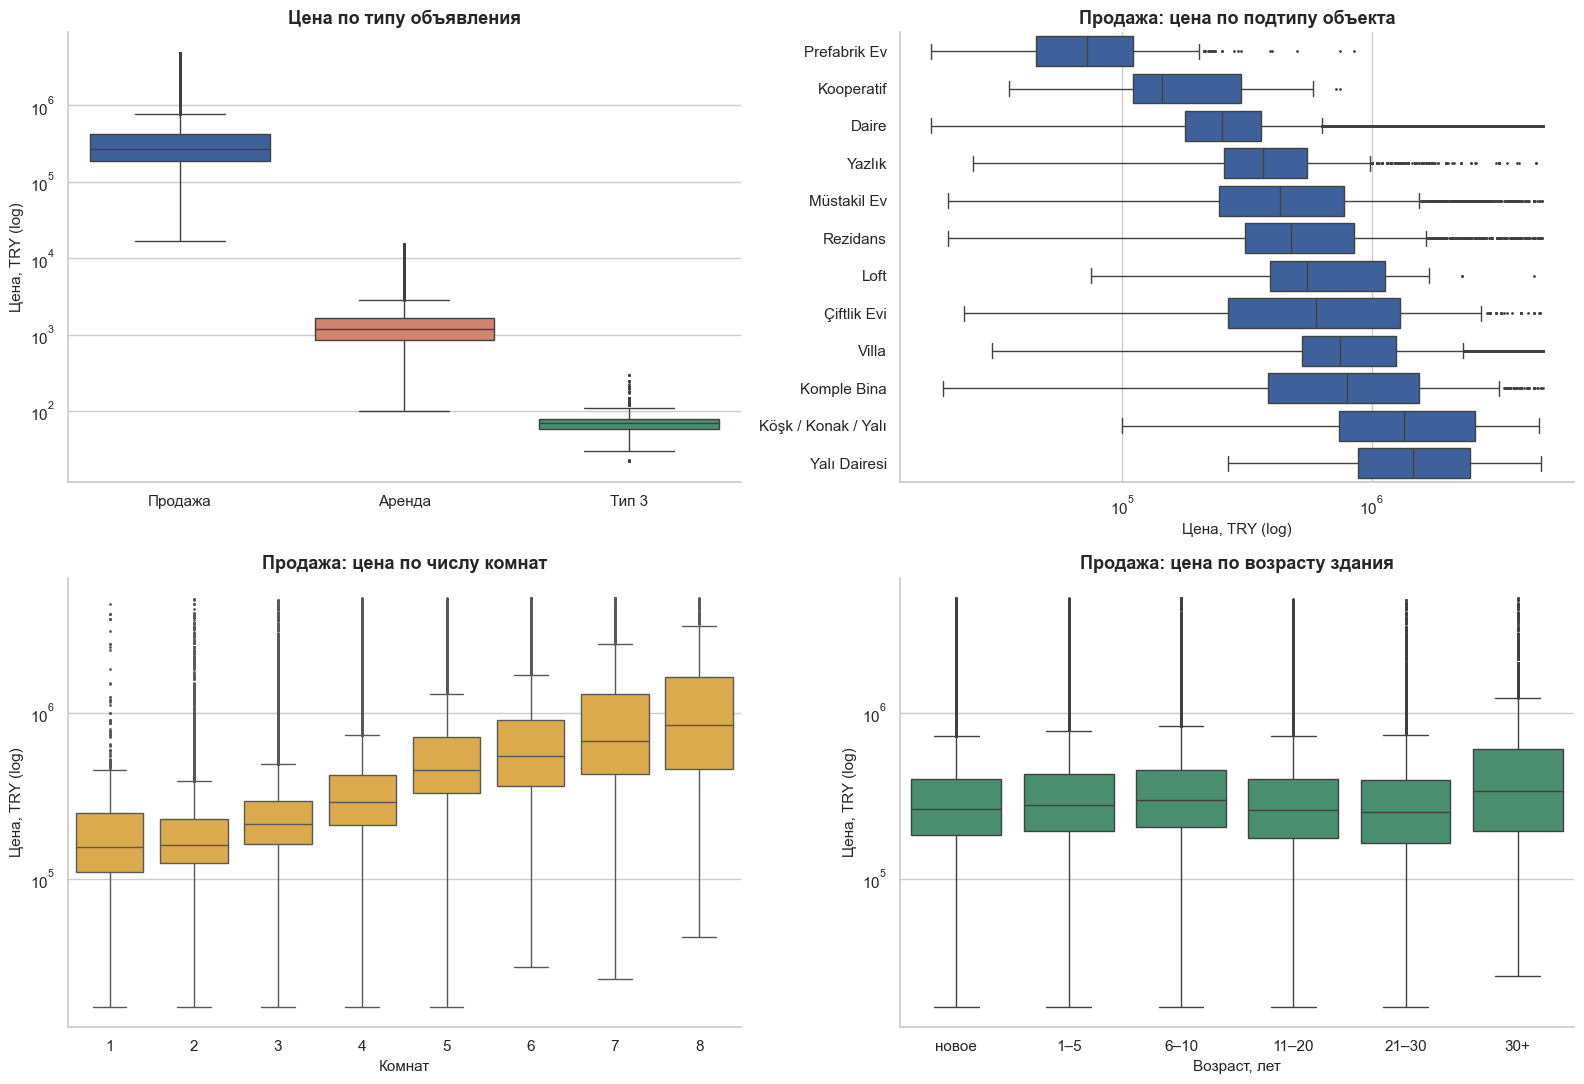

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))
sns.boxplot(data=ev, x="segment", y="price_try", order=list(COLORS), palette=COLORS, ax=axes[0, 0], fliersize=1); axes[0, 0].set_yscale("log")
axes[0, 0].set_title("Цена по типу объявления"); axes[0, 0].set_xlabel(""); axes[0, 0].set_ylabel("Цена, TRY (log)")

sale = ev[ev.segment == "Продажа"]
order = sale.groupby("sub_type")["price_try"].median().sort_values().index
sns.boxplot(data=sale, y="sub_type", x="price_try", order=order, color=COLORS["Продажа"], ax=axes[0, 1], fliersize=1); axes[0, 1].set_xscale("log")
axes[0, 1].set_title("Продажа: цена по подтипу объекта"); axes[0, 1].set_ylabel(""); axes[0, 1].set_xlabel("Цена, TRY (log)")

r = sale[sale.rooms_total.between(1, 8)]
sns.boxplot(data=r, x=r.rooms_total.astype(int), y="price_try", color=ACCENT, ax=axes[1, 0], fliersize=1); axes[1, 0].set_yscale("log")
axes[1, 0].set_title("Продажа: цена по числу комнат"); axes[1, 0].set_xlabel("Комнат"); axes[1, 0].set_ylabel("Цена, TRY (log)")

a = sale.assign(age_bin=pd.cut(sale.building_age, [-1, 0, 5, 10, 20, 30, 100], labels=["новое", "1–5", "6–10", "11–20", "21–30", "30+"]))
sns.boxplot(data=a.dropna(subset=["age_bin"]), x="age_bin", y="price_try", color=COLORS["Тип 3"], ax=axes[1, 1], fliersize=1); axes[1, 1].set_yscale("log")
axes[1, 1].set_title("Продажа: цена по возрасту здания"); axes[1, 1].set_xlabel("Возраст, лет"); axes[1, 1].set_ylabel("Цена, TRY (log)")
plt.tight_layout(); plt.show()

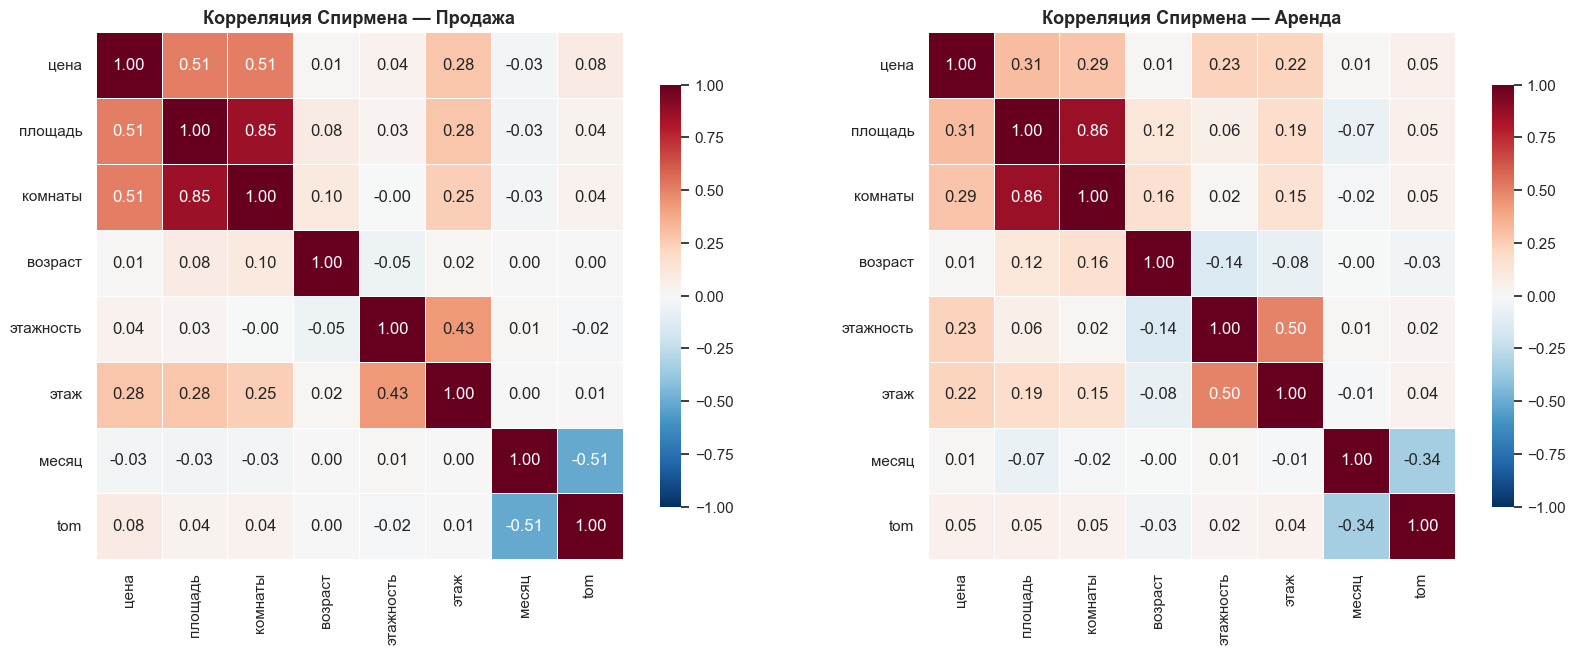

In [23]:
corr_cols = ["price_try", "size", "rooms_total", "building_age", "total_floors", "floor_num", "month_idx", "tom"]
names = ["цена", "площадь", "комнаты", "возраст", "этажность", "этаж", "месяц", "tom"]
fig, axes = plt.subplots(1, 2, figsize=(17, 6.5))
for ax, seg in zip(axes, ["Продажа", "Аренда"]):
    c = ev.loc[ev.segment == seg, corr_cols].corr(method="spearman")
    c.index = c.columns = names
    sns.heatmap(c, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, linewidths=.5, cbar_kws={"shrink": .8}, ax=ax)
    ax.set_title(f"Корреляция Спирмена — {seg}")
plt.tight_layout(); plt.show()

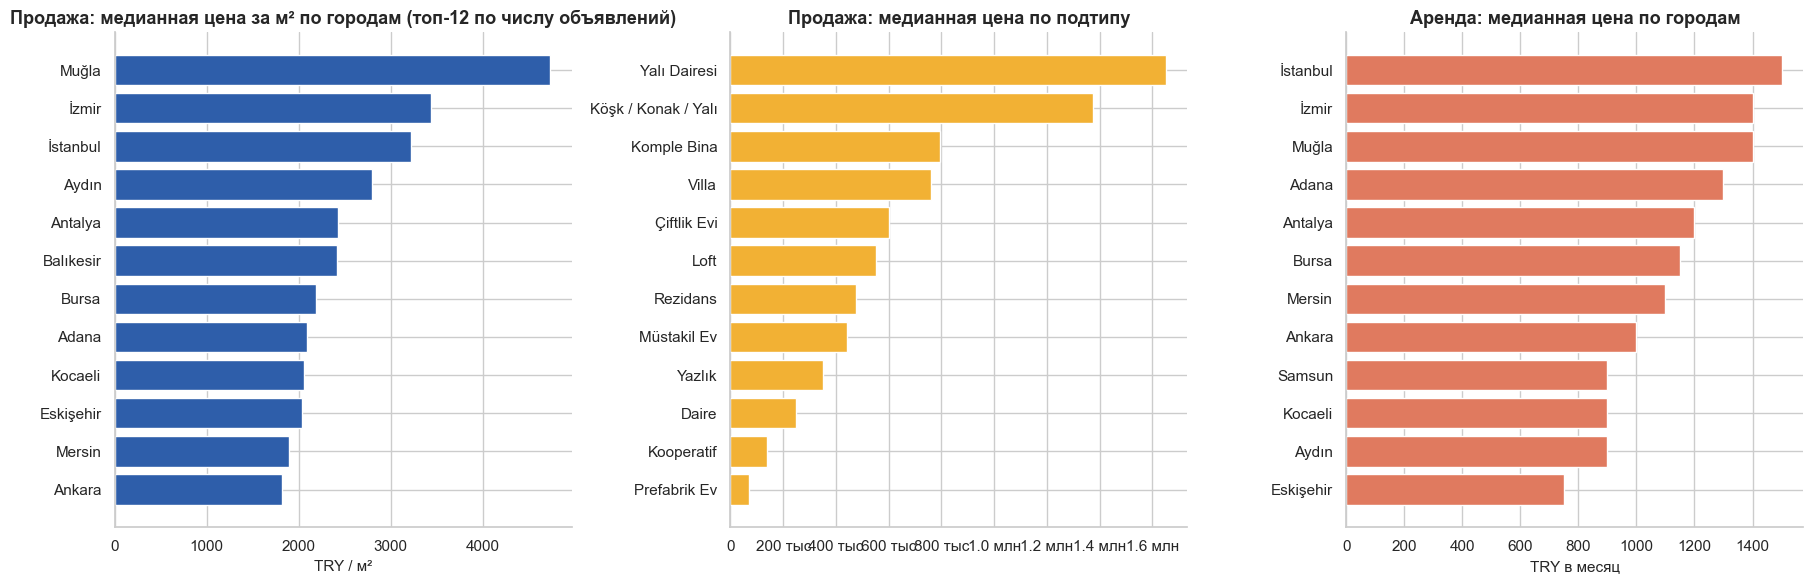

In [24]:
fig, axes = plt.subplots(1, 3, figsize=(18, 6))
sale = ev[(ev.segment == "Продажа") & ev["size"].notna()].copy()
sale["ppm"] = sale["price_try"] / sale["size"]          # цена за м² — только для EDA, в модель НЕ входит
top = sale["city"].value_counts().head(12).index
s1 = sale[sale.city.isin(top)].groupby("city")["ppm"].median().sort_values()
axes[0].barh(s1.index, s1.values, color=COLORS["Продажа"]); axes[0].set_title("Продажа: медианная цена за м² по городам (топ-12 по числу объявлений)"); axes[0].set_xlabel("TRY / м²")
s2 = sale.groupby("sub_type")["price_try"].median().sort_values()
axes[1].barh(s2.index, s2.values, color=ACCENT); axes[1].set_title("Продажа: медианная цена по подтипу"); axes[1].xaxis.set_major_formatter(mtick.FuncFormatter(fmt_money))
rent = ev[ev.segment == "Аренда"]
topr = rent["city"].value_counts().head(12).index
s3 = rent[rent.city.isin(topr)].groupby("city")["price_try"].median().sort_values()
axes[2].barh(s3.index, s3.values, color=COLORS["Аренда"]); axes[2].set_title("Аренда: медианная цена по городам"); axes[2].set_xlabel("TRY в месяц")
plt.tight_layout(); plt.show()

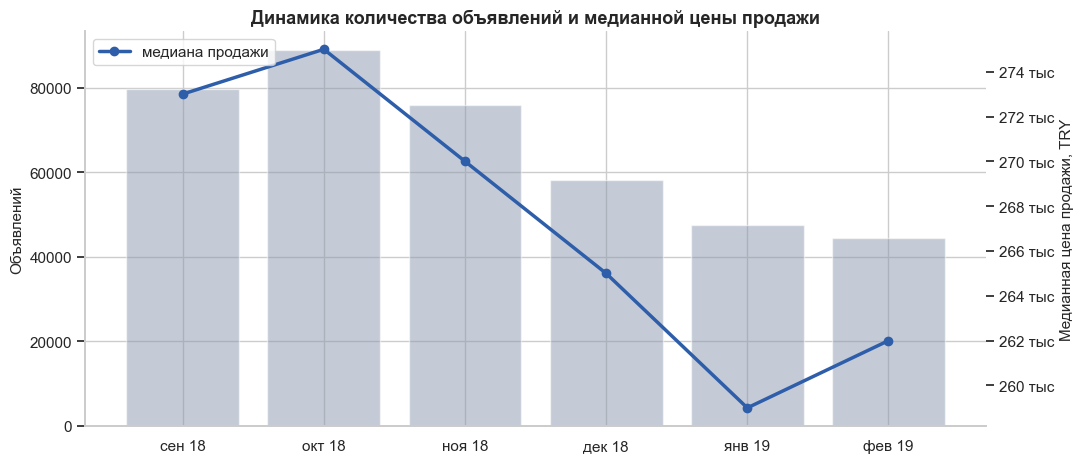

In [25]:
m = ev.groupby("month_idx").agg(n=("price_try", "size"))
m["sale_med"] = ev[ev.segment == "Продажа"].groupby("month_idx")["price_try"].median()
m["rent_med"] = ev[ev.segment == "Аренда"].groupby("month_idx")["price_try"].median()
labels = ["сен 18", "окт 18", "ноя 18", "дек 18", "янв 19", "фев 19"]
m = m.loc[(m.index >= 0) & (m.index <= 5)]
fig, ax = plt.subplots(figsize=(11, 4.8))
ax.bar([labels[i] for i in m.index], m.n, color=GREY, alpha=.5); ax.set_ylabel("Объявлений")
ax2 = ax.twinx(); ax2.grid(False)
ax2.plot([labels[i] for i in m.index], m.sale_med, "o-", color=COLORS["Продажа"], lw=2.5, label="медиана продажи")
ax2.set_ylabel("Медианная цена продажи, TRY"); ax2.yaxis.set_major_formatter(mtick.FuncFormatter(fmt_money)); ax2.legend(loc="upper left")
ax.set_title("Динамика количества объявлений и медианной цены продажи"); plt.tight_layout(); plt.show()

> **Выводы по визуальному анализу.**
> * Площадь и цена связаны степенной зависимостью: на log–log графике облако вытягивается вдоль прямой — поэтому в модель идёт `log(площадь)`.
> * Продажа и аренда различаются по цене на 2 порядка; **без признака «тип объявления» модель была бы бессмысленной.**
> * Цена зависит от подтипа (виллы / здания целиком дороже квартир), числа комнат и города/района.
> * Возраст здания и этаж связаны с ценой слабо и нелинейно; `tom` (срок экспозиции) почти не коррелирует с ценой.
> * За 6 месяцев динамика цен плавная — временной тренд не доминирует.

## 1.4 Анализ пропусков, дубликатов и аномалий

,Пропусков,"Доля, %"
furnished,403487,100.00
size,146006,36.19
end_date,137189,34.00
floor_no,35296,8.75
total_floor_count,28021,6.94
heating_type,27970,6.93
building_age,27390,6.79
price,715,0.18
price_currency,715,0.18
price_try,715,0.18


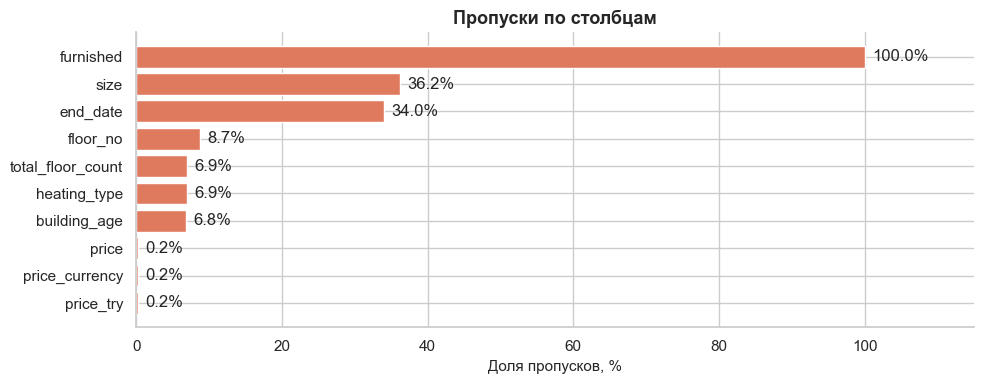

In [26]:
miss = pd.DataFrame({"Пропусков": df_raw.isna().sum(), "Доля, %": df_raw.isna().mean() * 100}).query("Пропусков > 0").sort_values("Доля, %", ascending=False)
display(miss)
fig, ax = plt.subplots(figsize=(10, 4))
bars = ax.barh(miss.index[::-1], miss["Доля, %"][::-1], color=COLORS["Аренда"])
for b, v in zip(bars, miss["Доля, %"][::-1]): ax.text(v + 1, b.get_y() + b.get_height()/2, f"{v:.1f}%", va="center")
ax.set_xlim(0, 115); ax.set_xlabel("Доля пропусков, %"); ax.set_title("Пропуски по столбцам")
plt.tight_layout(); plt.show()

In [27]:
SIG = ["address", "sub_type", "listing_type", "room_count", "size", "price", "price_currency",
       "building_age", "total_floor_count", "floor_no", "heating_type"]     # «паспорт» объекта без id, дат и tom
n_id_dup   = df_raw["id"].duplicated().sum()
n_full_dup = df_raw.drop(columns=["id"]).duplicated().sum()
n_sig_dup  = df_raw.duplicated(subset=SIG).sum()
print(f"Повторяющихся id:                              {n_id_dup:,}")
print(f"Полных дубликатов (без id):                    {n_full_dup:,}")
print(f"Один и тот же объект с той же ценой (по SIG):  {n_sig_dup:,}  ({n_sig_dup/len(df_raw):.1%} датасета)")
print("\nПример: одно и то же жильё, опубликованное повторно с разными id и датами")
ex = df_raw[df_raw.duplicated(subset=SIG, keep=False)].sort_values(SIG).head(6)
display(ex[["id", "address", "sub_type", "size", "price", "start_date", "end_date", "tom"]])

Повторяющихся id:                              0
Полных дубликатов (без id):                    11,559
Один и тот же объект с той же ценой (по SIG):  112,006  (27.8% датасета)

Пример: одно и то же жильё, опубликованное повторно с разными id и датами


,id,address,sub_type,size,price,start_date,end_date,tom
5422,5423,Adana/Aladağ/Ceritler,Müstakil Ev,260.00,"220,000.00",11/21/18,2/3/19,74
6054,6055,Adana/Aladağ/Ceritler,Müstakil Ev,260.00,"220,000.00",11/21/18,12/21/18,30
302371,302372,Adana/Ceyhan/Belediye Evleri,Daire,84.00,"41,000.00",12/12/18,1/11/19,30
323925,323926,Adana/Ceyhan/Belediye Evleri,Daire,84.00,"41,000.00",12/12/18,2/10/19,60
5055,5056,Adana/Ceyhan/Burhaniye,Daire,120.00,"190,000.00",11/13/18,12/13/18,30
5179,5180,Adana/Ceyhan/Burhaniye,Daire,120.00,"190,000.00",11/13/18,1/12/19,60


> **Важно.** Почти **каждое четвёртое объявление — повторная публикация** того же объекта (другой `id`, другие даты). При случайном разбиении такие копии оказываются и в обучении, и в тесте, а модель «узнаёт» объект по адресу и площади — оценки качества получаются нереалистично высокими. Поэтому дубликаты удаляются **до** разбиения (Этап 2).

In [28]:
sd = pd.to_datetime(df_raw.start_date, format="%m/%d/%y", errors="coerce")
ed = pd.to_datetime(df_raw.end_date,   format="%m/%d/%y", errors="coerce")
pp = df_raw["price_try"] / eda["size"]
checks = {
 "Цена ≤ 0":                                         (df_raw.price <= 0).sum(),
 "Цена не указана":                                  df_raw.price.isna().sum(),
 "Цена продажи < 10 000 TRY":                        ((df_raw.price_try < 1e4) & (df_raw.listing_type == 1)).sum(),
 "Цена > 100 млн TRY":                               (df_raw.price_try > 1e8).sum(),
 "Площадь < 10 м²":                                  (df_raw["size"] < 10).sum(),
 "Площадь > 5 000 м²":                               (df_raw["size"] > 5000).sum(),
 "Этаж выше этажности здания":                       (eda.floor_num > eda.total_floors).sum(),
 "Дата окончания раньше даты начала":                (ed < sd).sum(),
 "Продажа дешевле 1 000 TRY за м²":                  ((pp < 1000) & (df_raw.listing_type == 1)).sum(),
 "Комнаты не распознаны (значение «+»)":             eda.rooms_total.isna().sum() - 0,
 "Цена не в лирах (USD/EUR/GBP)":                    (df_raw.price_currency.fillna("TRY") != "TRY").sum(),
}
chk = pd.DataFrame({"Нарушений": checks}); chk["Доля, %"] = chk["Нарушений"] / len(df_raw) * 100
display(chk)

,Нарушений,"Доля, %"
Цена ≤ 0,45,0.01
Цена не указана,715,0.18
Цена продажи < 10 000 TRY,355,0.09
Цена > 100 млн TRY,30,0.01
Площадь < 10 м²,389,0.10
Площадь > 5 000 м²,221,0.05
Этаж выше этажности здания,2079,0.52
Дата окончания раньше даты начала,0,0.00
Продажа дешевле 1 000 TRY за м²,6036,1.50
Комнаты не распознаны (значение «+»),2898,0.72


## 1.5 Промежуточные выводы и гипотезы

In [29]:
sp = ev.assign(log_price=np.log(ev.price_try))
res = {}
for seg in ["Продажа", "Аренда"]:
    d = sp[sp.segment == seg]
    res[seg] = d[["size", "rooms_total", "building_age", "total_floors", "floor_num", "tom"]].corrwith(d["log_price"], method="spearman")
display(pd.DataFrame(res).round(2).rename(index={"size": "площадь", "rooms_total": "комнаты", "building_age": "возраст здания",
        "total_floors": "этажность", "floor_num": "этаж", "tom": "tom"}).rename_axis("корреляция Спирмена с log(цена)"))

,Продажа,Аренда
корреляция Спирмена с log(цена),,
площадь,0.51,0.31
комнаты,0.51,0.29
возраст здания,0.01,0.01
этажность,0.04,0.23
этаж,0.28,0.22
tom,0.08,0.05


**Гипотезы о факторах цены** (подтверждены графиками выше):

1. **H1 — тип объявления** (продажа/аренда) — самый сильный фактор: цены различаются на два порядка (см. бимодальное распределение).
2. **H2 — площадь:** цена растёт как степенная функция площади (log–log тренд, корреляция Спирмена ≈ 0.5 для продажи).
3. **H3 — локация** (город → район → квартал): медианная цена за м² различается в разы между городами.
4. **H4 — подтип объекта и число комнат:** виллы, здания целиком, большие квартиры дороже; эффект «комнаты» частично дублирует площадь (мультиколлинеарность).
5. **H5 — возраст здания и `tom` — слабые факторы** (корреляция Спирмена с ценой ≈ 0.0–0.1), этаж — умеренный (≈ 0.2–0.3). `tom` к тому же неизвестен на момент публикации → в модель не включается.

**Выявленные проблемы данных:** пустой `furnished`; 36 % пропусков площади; ~28 % повторных публикаций; ошибки ввода цены и площади; смешение валют; нечисловые значения этажа/возраста/комнат (диапазоны, «Müstakil», «+»).

---
# Этап 2. Предварительная обработка данных
## 2.1 Стратегия работы с пропусками

| Признак | Пропусков | Стратегия | Обоснование |
|---|---|---|---|
| `furnished` | 100 % | **удалить столбец** | информации нет |
| `price` / `price_currency` | 0.2 % | **удалить строки** | цель нельзя восстанавливать — иначе модель учится на выдуманных ответах |
| `size` | 36 % | **медиана по группе** (`sub_type`, число комнат, тип объявления) + флаг `size_missing` | площадь — главный признак; групповая медиана точнее глобальной. Строки удалять нельзя: потеряем треть данных |
| `building_age` | 7 % | медиана по (город, подтип) + флаг | значение не критично, флаг сохраняет сам факт пропуска |
| `total_floors`, `floor_no` | 7–9 % | медиана по подтипу; нечисловые этажи → отдельная категория `floor_kind` | «Müstakil», «Bahçe katı» — это информация, а не пропуск |
| `heating_type` | 7 % | категория `unknown` | пропуск как самостоятельное значение |
| `end_date`, `tom` | 34 % / 0 % | **не используются** | известны только после снятия объявления (утечка из будущего) |

Все медианы вычисляются **только на train** (класс `GroupMedianImputer` внутри `Pipeline`).

## 2.2 Выбросы и скошенность
* **Цена (цель):** строки с ценой ≤ 0 удаляются; затем внутри каждого типа объявления удаляются значения за пределами **3·IQR в лог-шкале** (ошибки ввода вроде 2·10⁹ TRY). Затем цель **логарифмируется** `log1p(price)`.
* **Площадь:** значения вне диапазона 10–5 000 м² считаются ошибками ввода → `NaN` → импутация. В модель идёт `log(size)`.
* **Валюты:** USD/EUR/GBP приводятся к TRY (приблизительные курсы на конец 2018 г.).
* **Дубликаты:** удаляются повторные публикации объекта (одинаковый «паспорт» + цена).
* **20 тестовых объектов**, их точные копии и «почти-копии» (тот же адрес, подтип, число комнат и тип объявления, цена в пределах ±5 %) удаляются из обучающих данных — иначе модель могла бы просто «вспомнить» ответ.

In [32]:
test_df = pd.read_csv("test_real_estate_samples.csv", dtype=STR_COLS)
print(f"Тестовых объектов: {len(test_df)}  (хранятся отдельно, в обучении не участвуют)")

def row_hash(d):
    return pd.util.hash_pandas_object(d[SIG].astype(str).fillna("NA"), index=False)

steps = []
d = df_raw.drop(columns=["furnished", "type"]);                              steps.append(("Исходные данные", len(d)))
d = d[d["price"].notna() & (d["price"] > 0)].copy();                         steps.append(("− цена пустая или ≤ 0", len(d)))
d["price_try"] = d["price"] * d["price_currency"].map(FX_TO_TRY)
test_hashes = set(row_hash(test_df))
leak = d["id"].isin(test_df["id"]) | row_hash(d).isin(test_hashes)
d = d[~leak];                                                                steps.append(("− 20 тестовых объектов и их точные копии", len(d)))
# «почти-копии»: тот же адрес, подтип, комнаты, тип объявления и цена в пределах ±5 % (отличаются, например, отоплением)
key = ["address", "listing_type", "sub_type", "room_count"]
mm = d[key + ["price_try"]].reset_index().merge(test_df[key + ["price"]].rename(columns={"price": "price_t"}), on=key)
near_idx = mm.loc[(mm["price_try"] / mm["price_t"]).between(0.95, 1.05), "index"].unique()
d = d.drop(index=near_idx);                                                  steps.append(("− почти-копии тестовых объектов (цена ±5 %)", len(d)))
d = d.drop_duplicates(subset=SIG);                                           steps.append(("− повторные публикации (дубликаты)", len(d)))
d["segment"] = d["listing_type"].map(SEG)
keep = log_iqr_mask(d["price_try"], d["segment"], k=3.0)
d = d[keep];                                                                 steps.append(("− выбросы цены (3·IQR в лог-шкале)", len(d)))
data = d.reset_index(drop=True)

wf = pd.DataFrame(steps, columns=["Шаг", "Строк осталось"])
wf["Удалено"] = (-wf["Строк осталось"].diff()).fillna(0).astype(int)
wf["Доля от исходных, %"] = wf["Строк осталось"] / len(df_raw) * 100
display(wf)
print(f"\nИтого для моделирования: {len(data):,} объектов "
      f"({len(data)/len(df_raw):.0%} исходных). Потери — это в основном дубликаты, а не «полезные» данные.")

Тестовых объектов: 20  (хранятся отдельно, в обучении не участвуют)


,Шаг,Строк осталось,Удалено,"Доля от исходных, %"
0,Исходные данные,403487,0,100.00
1,− цена пустая или ≤ 0,402727,760,99.81
2,− 20 тестовых объектов и их точные копии,402698,29,99.80
3,− почти-копии тестовых объектов (цена ±5 %),402640,58,99.79
4,− повторные публикации (дубликаты),290977,111663,72.12
5,− выбросы цены (3·IQR в лог-шкале),286849,4128,71.09



Итого для моделирования: 286,849 объектов (71% исходных). Потери — это в основном дубликаты, а не «полезные» данные.


,Асимметрия
Величина,
"price (исходная, TRY)",302.26
price (после очистки),4.89
log(price) (после очистки) — целевая переменная,-0.75
"size (исходная, м²)",77.65
size (после фильтра 10–5000 м²),17.37
log(size),0.71


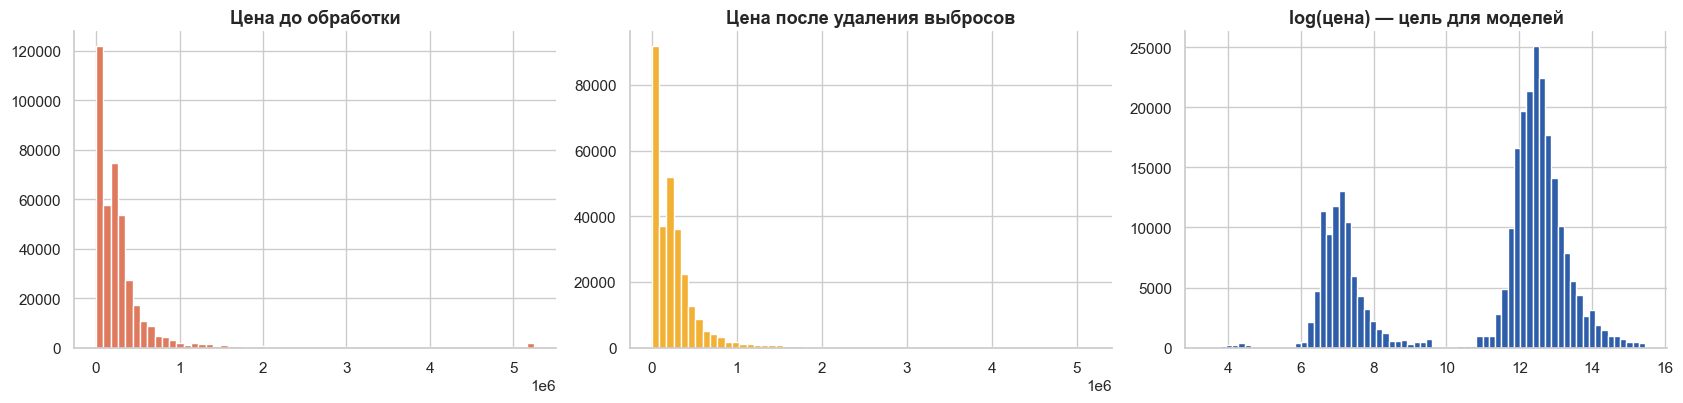

In [33]:
# Эффект обработки на форму распределения
from scipy import stats
before = df_raw.loc[df_raw.price_try > 0, "price_try"]
rows = [("price (исходная, TRY)", stats.skew(before)),
        ("price (после очистки)", stats.skew(data["price_try"])),
        ("log(price) (после очистки) — целевая переменная", stats.skew(np.log1p(data["price_try"]))),
        ("size (исходная, м²)", stats.skew(df_raw["size"].dropna())),
        ("size (после фильтра 10–5000 м²)", stats.skew(eda["size"].dropna())),
        ("log(size)", stats.skew(np.log(eda["size"].dropna())))]
display(pd.DataFrame(rows, columns=["Величина", "Асимметрия"]).set_index("Величина"))
fig, axes = plt.subplots(1, 3, figsize=(17, 4.2))
axes[0].hist(before.clip(upper=before.quantile(.995)), bins=60, color=COLORS["Аренда"]); axes[0].set_title("Цена до обработки")
axes[1].hist(data["price_try"], bins=60, color=ACCENT); axes[1].set_title("Цена после удаления выбросов")
axes[2].hist(np.log1p(data["price_try"]), bins=70, color=COLORS["Продажа"]); axes[2].set_title("log(цена) — цель для моделей")
plt.tight_layout(); plt.show()

## 2.3 Кодирование категориальных признаков

| Признак | Кардинальность | Метод | Почему |
|---|---|---|---|
| `sub_type`, `heating_type`, `floor_kind`, `listing_type` | 3–17 | **One-Hot** (редкие категории < 30 объектов → «infrequent») | номинальные, мало значений |
| `building_age`, `total_floor_count`, `room_count`, `floor_no` | — | **числовой разбор** («6-10 arası» → 8, «3+1» → 3 + 1 и т. д.) | порядок категорий имеет смысл |
| город / район / квартал (+ тип объявления) | 82 / ~900 / 7 800 | **Target Encoding** со сглаживанием и 5-fold cross-fitting (`sklearn.TargetEncoder`) | One-Hot дал бы тысячи столбцов; cross-fitting не даёт утечки внутри train |

Ключ локации включает тип объявления (`Город/Район|1`), потому что средний уровень цен продажи и аренды в одном и том же районе несопоставим.

## 2.4 Feature Engineering и мультиколлинеарность
Создаваемые признаки: `log_size`, `rooms_main`/`rooms_extra`/`rooms_total`, `building_age` (числом), `total_floors`, `floor_num`, `floor_kind`, `floor_ratio` (этаж / этажность), `month_idx` (сезонность), флаги пропусков, три уровня локации.

> ❌ **Не создаётся** «цена за м²» как признак: она вычисляется из целевой переменной. Цена за м² используется только как инструмент EDA.

In [34]:
# Окончательное разбиение: train 70 % / validation 15 % / test 15 %, стратификация по типу объявления
from sklearn.model_selection import train_test_split
X_all = data[RAW_REQUIRED + ["id"]]
y_all = np.log1p(data["price_try"])               # цель — логарифм цены
strat = data["listing_type"]

idx_tv, idx_test = train_test_split(data.index, test_size=0.15, stratify=strat, random_state=RANDOM_STATE)
idx_train, idx_val = train_test_split(idx_tv, test_size=0.15 / 0.85, stratify=strat[idx_tv], random_state=RANDOM_STATE)

train, val, test = data.loc[idx_train], data.loc[idx_val], data.loc[idx_test]
y_train, y_val, y_test = y_all[idx_train], y_all[idx_val], y_all[idx_test]

# Проверки на утечку
assert not (set(train.id) & set(val.id)) and not (set(train.id) & set(test.id)) and not (set(val.id) & set(test.id))
assert not (set(data.id) & set(test_df.id)), "тестовые объекты из задания попали в обучающие данные!"
assert not (set(row_hash(train)) & set(row_hash(test))), "копии объектов есть и в train, и в test!"
print(pd.DataFrame({"Выборка": ["Train", "Validation", "Test"], "Объектов": [len(train), len(val), len(test)],
                    "Доля, %": [len(train)/len(data)*100, len(val)/len(data)*100, len(test)/len(data)*100],
                    "Продажа, %": [(s.listing_type==1).mean()*100 for s in (train, val, test)],
                    "Аренда, %": [(s.listing_type==2).mean()*100 for s in (train, val, test)]}).to_string(index=False))
print("\n✔ Пересечений id между выборками нет, копий объектов между train и test нет, тестовые объекты задания не использованы.")

   Выборка  Объектов  Доля, %  Продажа, %  Аренда, %
     Train    200793    70.00       69.37      30.15
Validation     43028    15.00       69.37      30.15
      Test     43028    15.00       69.37      30.15

✔ Пересечений id между выборками нет, копий объектов между train и test нет, тестовые объекты задания не использованы.


### Мультиколлинеарность (VIF)
VIF считается по обучающей выборке на признаках после импутации. Правило: VIF > 10 — признак удаляется. Функция реализована вручную (VIFⱼ = 1 / (1 − R²ⱼ), где R²ⱼ — регрессия признака j на все остальные).

In [35]:
from sklearn.pipeline import Pipeline
feat_pipe = Pipeline([("f", FeatureBuilder()), ("imp", GroupMedianImputer(IMPUTE_RULES)), ("d", DerivedFeatures())]).fit(train)
F = feat_pipe.transform(train)

def vif_table(frame, cols):
    A = frame[cols].dropna().to_numpy(float); out = []
    for j, c in enumerate(cols):
        y = A[:, j]; X = np.column_stack([np.ones(len(A)), np.delete(A, j, axis=1)])
        beta, *_ = np.linalg.lstsq(X, y, rcond=None)
        r2 = 1 - ((y - X @ beta) ** 2).sum() / ((y - y.mean()) ** 2).sum()
        out.append(1 / (1 - r2) if r2 < 1 else np.inf)
    return pd.Series(out, index=cols, name="VIF").sort_values(ascending=False)

cand = ["size", "log_size", "rooms_main", "rooms_extra", "rooms_total", "building_age", "total_floors", "floor_num", "floor_ratio", "month_idx"]
v1 = vif_table(F, cand)
final_cols = ["log_size", "rooms_total", "rooms_extra", "building_age", "total_floors", "floor_num", "floor_ratio", "month_idx"]
v2 = vif_table(F, final_cols)
display(pd.concat([v1.rename("VIF (все кандидаты)"), v2.rename("VIF (итоговый набор)")], axis=1))

,VIF (все кандидаты),VIF (итоговый набор)
rooms_main,inf,NaN
rooms_extra,inf,1.35
rooms_total,inf,4.14
log_size,6.14,3.59
floor_num,4.65,4.65
total_floors,3.15,3.16
floor_ratio,2.96,2.96
size,2.59,NaN
building_age,1.02,1.02
month_idx,1.00,1.00


> **Решение.** `rooms_total = rooms_main + rooms_extra` — точная линейная комбинация (VIF = ∞), поэтому `rooms_main` удаляется. Из пары `size` / `log_size` оставляем `log_size` — цель логарифмирована, и зависимость «log-цена ~ log-площадь» близка к линейной (см. EDA). В итоговом наборе **максимальный VIF ≈ 4.6 < 10** — серьёзной мультиколлинеарности нет. Для деревьев мультиколлинеарность не опасна, но для линейной модели критична.

## 2.5 Масштабирование
| Модели | Масштабирование | Почему |
|---|---|---|
| Ridge (линейная) | **StandardScaler** | регуляризация и коэффициенты чувствительны к масштабу признаков |
| Decision Tree, Random Forest, Gradient Boosting | **не нужно** | разбиения по порогам инвариантны к монотонному преобразованию |

Функция `make_preprocessor(scale=True/False)` включает/выключает scaler. Scaler (как и все кодировщики и импутеры) обучается **только на train** внутри `Pipeline`, поэтому утечки данных нет.

## 2.6 Итог предобработки

In [36]:
prep_demo = make_preprocessor(scale=False).fit(train, y_train)
Xd = prep_demo.transform(train.head(5))
print(f"Признаков на входе модели: {Xd.shape[1]}  (числовых: {len(NUM_COLS)}, One-Hot: {Xd.shape[1]-len(NUM_COLS)-3}, Target-encoding: 3)")
display(Xd.iloc[:, list(range(8)) + [-3, -2, -1]])

Признаков на входе модели: 60  (числовых: 11, One-Hot: 46, Target-encoding: 3)


,log_size,rooms_total,rooms_extra,building_age,total_floors,floor_num,floor_ratio,month_idx,loc_city,loc_district,loc_neigh
66533,4.98,4.00,1.00,0.00,3.00,2.00,0.67,3,12.41,12.23,12.54
156162,4.74,4.00,1.00,13.00,4.00,3.00,0.75,5,12.41,11.99,12.19
45533,4.70,3.00,1.00,18.00,3.00,2.00,0.67,3,7.09,7.07,6.82
237130,5.16,5.00,1.00,0.00,10.00,1.00,0.10,0,12.25,12.24,12.89
120203,4.50,3.00,1.00,5.00,4.00,1.00,0.25,2,12.80,12.84,12.82


---
# Этап 3. Построение моделей регрессии
## 3.1 Набор моделей

Выбраны **4 модели разной природы** + тривиальный baseline для ориентира. Целевая переменная — `log1p(price)`; метрики дополнительно пересчитываются в лирах (`expm1`).

| № | Модель | Природа | Масштабирование |
|---|---|---|---|
| 0 | *Baseline:* среднее log-цены по типу объявления | эталон «без интеллекта» | — |
| 1 | **Ridge** | линейная (с L2-регуляризацией) | StandardScaler |
| 2 | **Decision Tree** | одиночное дерево | не нужно |
| 3 | **Random Forest** | ансамбль, бэггинг | не нужно |
| 4 | **HistGradientBoosting** | ансамбль, бустинг (аналог LightGBM из `sklearn`) | не нужно |

Каждая модель — это единый `Pipeline`: *разбор признаков → импутация → производные признаки → кодирование → (масштабирование) → модель*. Поэтому при кросс-валидации все преобразования заново обучаются на обучающей части фолда — **утечки нет**.

In [37]:
from sklearn.linear_model import Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.model_selection import RandomizedSearchCV, KFold
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, median_absolute_error
from scipy.stats import loguniform

CACHE = Path("cache"); CACHE.mkdir(exist_ok=True)
def cached(name, fn):
    """Тяжёлые вычисления сохраняются в cache/. Чтобы пересчитать — удалите папку cache."""
    p = CACHE / f"{name}.joblib"
    if p.exists():
        return joblib.load(p)
    obj = fn(); joblib.dump(obj, p, compress=3); return obj

def evaluate(y_log_true, y_log_pred):
    """Метрики и в log-шкале (на чём учится модель), и в лирах (что важно пользователю)."""
    yt, yp = np.expm1(np.asarray(y_log_true)), np.expm1(np.asarray(y_log_pred))
    return {"MAE, TRY": mean_absolute_error(yt, yp),
            "RMSE, TRY": np.sqrt(mean_squared_error(yt, yp)),
            "MAPE, %": np.mean(np.abs(yt - yp) / yt) * 100,
            "MedAE, TRY": median_absolute_error(yt, yp),
            "R² (TRY)": r2_score(yt, yp),
            "MAE (log)": mean_absolute_error(y_log_true, y_log_pred),
            "RMSE (log)": np.sqrt(mean_squared_error(y_log_true, y_log_pred)),
            "R² (log)": r2_score(y_log_true, y_log_pred)}

def make_pipe(name, **params):
    spec = {"Ridge": (True, lambda: Ridge(random_state=RANDOM_STATE)),
            "Decision Tree": (False, lambda: DecisionTreeRegressor(random_state=RANDOM_STATE)),
            "Random Forest": (False, lambda: RandomForestRegressor(n_jobs=-1, random_state=RANDOM_STATE)),
            "HistGradientBoosting": (False, lambda: HistGradientBoostingRegressor(random_state=RANDOM_STATE))}[name]
    pipe = Pipeline([("prep", make_preprocessor(scale=spec[0])), ("model", spec[1]())])
    return pipe.set_params(**params) if params else pipe

MODEL_NAMES = ["Ridge", "Decision Tree", "Random Forest", "HistGradientBoosting"]
Xtr, Xva, Xte = train[RAW_REQUIRED], val[RAW_REQUIRED], test[RAW_REQUIRED]
print("Модели и пайплайны определены")

Модели и пайплайны определены


## 3.2 Baseline: модели с параметрами по умолчанию
Все модели обучаются на **train** и оцениваются на **validation**. Для Random Forest число деревьев ограничено 40 (вместо 100) только из соображений времени и памяти; остальные параметры — по умолчанию.

In [38]:
def run_baselines():
    out = {}
    # эталон: среднее log-цены по типу объявления
    mean_by_lt = y_train.groupby(train["listing_type"]).mean()
    p = val["listing_type"].map(mean_by_lt).to_numpy()
    out["Baseline (тип объявления)"] = {**evaluate(y_val, p), "fit, c": 0.0, "predict, мс/1000": 0.0}
    for name in MODEL_NAMES:
        pipe = make_pipe(name, **({"model__n_estimators": 40} if name == "Random Forest" else {}))
        t0 = time.time(); pipe.fit(Xtr, y_train); fit_t = time.time() - t0
        t0 = time.time(); pred = pipe.predict(Xva); inf_t = (time.time() - t0) / len(Xva) * 1000 * 1000
        out[name] = {**evaluate(y_val, pred), "fit, c": fit_t, "predict, мс/1000": inf_t}
        print(f"  ✓ {name:<22} MAE(log)={out[name]['MAE (log)']:.4f}  R²(log)={out[name]['R² (log)']:.4f}  fit={fit_t:.0f}s")
        del pipe
    return pd.DataFrame(out).T

df_base = cached("baseline_v2", run_baselines)
display(df_base[["MAE, TRY", "RMSE, TRY", "MAPE, %", "R² (TRY)", "MAE (log)", "R² (log)", "fit, c", "predict, мс/1000"]])

  ✓ Ridge                  MAE(log)=0.2806  R²(log)=0.9763  fit=2s
  ✓ Decision Tree          MAE(log)=0.3096  R²(log)=0.9674  fit=4s
  ✓ Random Forest          MAE(log)=0.2259  R²(log)=0.9829  fit=9s
  ✓ HistGradientBoosting   MAE(log)=0.2411  R²(log)=0.9820  fit=4s


,"MAE, TRY","RMSE, TRY","MAPE, %",R² (TRY),MAE (log),R² (log),"fit, c","predict, мс/1000"
Baseline (тип объявления),"148,586.56","386,697.50",54.46,0.15,0.50,0.93,0.00,0.00
Ridge,"86,257.30","253,193.58",31.81,0.63,0.28,0.98,1.91,9.05
Decision Tree,"101,329.46","295,685.90",37.93,0.50,0.31,0.97,3.72,7.20
Random Forest,"72,145.28","221,097.42",24.85,0.72,0.23,0.98,9.30,12.64
HistGradientBoosting,"76,674.92","225,904.78",26.18,0.71,0.24,0.98,4.00,8.46


> **Как читать таблицу.** Даже baseline, знающий только «продажа или аренда», получает **R² (log) ≈ 0.95** — потому что разница между продажей и арендой сама создаёт огромную дисперсию. Поэтому R² в лог-шкале нельзя считать показателем качества «в вакууме»: смотрим на **MAE (log)** (≈ средняя относительная ошибка), **MAPE** и метрики **в лирах**, а также на то, насколько модели лучше baseline.

## 3.3 Подбор гиперпараметров (RandomizedSearchCV + кросс-валидация)
* Поиск выполняется **на train** (validation и test не используются!): 3-fold CV, метрика — MAE в log-шкале (≈ относительная ошибка).
* Для скорости поиск идёт на случайной подвыборке train из **40 000** строк; затем лучшая конфигурация **переобучается на всём train**.

In [39]:
SEARCH = {
    "Ridge": ({"model__alpha": loguniform(1e-3, 1e2)}, 8),
    "Decision Tree": ({"model__max_depth": [8, 12, 16, 20, 28, None], "model__min_samples_leaf": [1, 3, 5, 10, 20, 50],
                       "model__min_samples_split": [2, 5, 10, 20]}, 10),
    "Random Forest": ({"model__n_estimators": [60, 100], "model__max_depth": [16, 24, None], "model__min_samples_leaf": [3, 5, 10, 20],
                       "model__max_features": [0.4, 0.6, 0.8], "model__max_samples": [0.4, 0.6]}, 6),
    "HistGradientBoosting": ({"model__learning_rate": [0.05, 0.08, 0.12], "model__max_iter": [300, 600, 1000],
                              "model__max_leaf_nodes": [31, 63, 127], "model__min_samples_leaf": [20, 50, 100],
                              "model__l2_regularization": [0, 1, 10]}, 8),
}
tune_idx = train.sample(40000, random_state=RANDOM_STATE).index
Xt, yt_ = train.loc[tune_idx, RAW_REQUIRED], y_train[tune_idx]
cv = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

def run_search():
    res = {}
    for name in MODEL_NAMES:
        space, n_iter = SEARCH[name]
        t0 = time.time()
        rs = RandomizedSearchCV(make_pipe(name), space, n_iter=n_iter, cv=cv, scoring={"mae": "neg_mean_absolute_error", "r2": "r2"},
                                refit=False, random_state=RANDOM_STATE, n_jobs=1)
        rs.fit(Xt, yt_)
        r = pd.DataFrame(rs.cv_results_)
        best = r.loc[r["rank_test_mae"].idxmin()]
        res[name] = {"params": {k.replace("model__", ""): (v.item() if hasattr(v, "item") else v) for k, v in best["params"].items()},
                     "cv_mae": -best["mean_test_mae"], "cv_r2": best["mean_test_r2"], "time": time.time() - t0, "n_iter": n_iter}
        print(f"  ✓ {name:<22} CV MAE(log)={res[name]['cv_mae']:.4f}  R²={res[name]['cv_r2']:.4f}  ({res[name]['time']:.0f}s)")
    return res

tuning = cached("tuning_v2", run_search)
display(pd.DataFrame({n: {"Лучшие параметры": str(t["params"]), "CV MAE (log)": round(t["cv_mae"], 4), "CV R² (log)": round(t["cv_r2"], 4),
                          "Конфигураций": t["n_iter"], "Время, c": round(t["time"])} for n, t in tuning.items()}).T)

  ✓ Ridge                  CV MAE(log)=0.3047  R²=0.9721  (8s)
  ✓ Decision Tree          CV MAE(log)=0.2921  R²=0.9747  (14s)
  ✓ Random Forest          CV MAE(log)=0.2555  R²=0.9798  (12s)
  ✓ HistGradientBoosting   CV MAE(log)=0.2512  R²=0.9807  (94s)


,Лучшие параметры,CV MAE (log),CV R² (log),Конфигураций,"Время, c"
Ridge,{'alpha': 56.69849511478853},0.30,0.97,8,8
Decision Tree,"{'min_samples_split': 5, 'min_samples_leaf': 5...",0.29,0.97,10,14
Random Forest,"{'n_estimators': 60, 'min_samples_leaf': 3, 'm...",0.26,0.98,6,12
HistGradientBoosting,"{'min_samples_leaf': 50, 'max_leaf_nodes': 63,...",0.25,0.98,8,94


## 3.4 Финальное обучение и сравнение моделей
Лучшие конфигурации обучаются на **всём train**. Модели сравниваются на **validation** (по ней делается выбор) и на **test** (только итоговая оценка — тест при подборе не использовался).

In [40]:
def fit_final():
    models = {}
    for name in MODEL_NAMES:
        t0 = time.time()
        pipe = make_pipe(name, **{f"model__{k}": v for k, v in tuning[name]["params"].items()})
        pipe.fit(Xtr, y_train); pipe.fit_time_ = time.time() - t0
        models[name] = pipe
        print(f"  ✓ {name:<22} обучена за {pipe.fit_time_:.0f} c")
    return models

models = cached("final_models_v2", fit_final)

pred_val  = {n: m.predict(Xva) for n, m in models.items()}
pred_test = {n: m.predict(Xte) for n, m in models.items()}
t0 = time.time(); _ = models["HistGradientBoosting"].predict(Xva); _t = time.time() - t0

rows_val, rows_test = {}, {}
for n, m in models.items():
    t0 = time.time(); m.predict(Xva.head(5000)); inf = (time.time() - t0) / 5000 * 1000 * 1000
    rows_val[n]  = {**evaluate(y_val, pred_val[n]),  "fit, c": m.fit_time_, "predict, мс/1000": inf}
    rows_test[n] = {**evaluate(y_test, pred_test[n])}
mean_by_lt = y_train.groupby(train["listing_type"]).mean()
base_val  = evaluate(y_val,  val["listing_type"].map(mean_by_lt))
base_test = evaluate(y_test, test["listing_type"].map(mean_by_lt))
df_val  = pd.DataFrame({"Baseline (тип объявления)": base_val, **rows_val}).T
df_test = pd.DataFrame({"Baseline (тип объявления)": base_test, **rows_test}).T
COLS = ["MAE, TRY", "RMSE, TRY", "MAPE, %", "MedAE, TRY", "R² (TRY)", "MAE (log)", "RMSE (log)", "R² (log)"]

display(Markdown("### Validation (по нему выбираем модель)")); display(df_val[COLS + ["fit, c", "predict, мс/1000"]])
display(Markdown("### Test (итоговая оценка, 15 % данных)")); display(df_test[COLS])

  ✓ Ridge                  обучена за 2 c
  ✓ Decision Tree          обучена за 3 c
  ✓ Random Forest          обучена за 4 c
  ✓ HistGradientBoosting   обучена за 16 c


### Validation (по нему выбираем модель)

,"MAE, TRY","RMSE, TRY","MAPE, %","MedAE, TRY",R² (TRY),MAE (log),RMSE (log),R² (log),"fit, c","predict, мс/1000"
Baseline (тип объявления),"148,586.56","386,697.50",54.46,"60,446.58",0.15,0.50,0.68,0.93,NaN,NaN
Ridge,"86,252.60","253,466.65",31.82,"26,534.42",0.63,0.28,0.40,0.98,1.86,11.02
Decision Tree,"82,000.29","239,316.98",28.29,"22,699.09",0.67,0.26,0.38,0.98,2.91,9.83
Random Forest,"72,292.46","222,548.52",24.50,"19,623.71",0.72,0.22,0.34,0.98,4.31,12.46
HistGradientBoosting,"72,537.92","216,735.01",24.79,"20,402.73",0.73,0.23,0.34,0.98,16.29,18.50


### Test (итоговая оценка, 15 % данных)

,"MAE, TRY","RMSE, TRY","MAPE, %","MedAE, TRY",R² (TRY),MAE (log),RMSE (log),R² (log)
Baseline (тип объявления),"150,478.79","390,481.62",53.81,"61,553.42",0.14,0.50,0.68,0.93
Ridge,"88,049.90","259,207.44",30.81,"27,068.61",0.62,0.28,0.40,0.98
Decision Tree,"81,886.88","240,970.45",26.89,"22,867.27",0.67,0.25,0.37,0.98
Random Forest,"72,804.07","223,571.73",23.40,"19,741.91",0.72,0.22,0.33,0.98
HistGradientBoosting,"73,273.66","220,170.13",23.89,"20,952.36",0.73,0.23,0.33,0.98


In [41]:
# Сводка: что дали подбор гиперпараметров и ансамбли относительно baseline (validation)
cmp = pd.DataFrame({"MAE (log), default": df_base["MAE (log)"], "MAE (log), tuned": df_val["MAE (log)"],
                    "MAPE %, default": df_base["MAPE, %"], "MAPE %, tuned": df_val["MAPE, %"],
                    "R² (TRY), default": df_base["R² (TRY)"], "R² (TRY), tuned": df_val["R² (TRY)"]}).loc[["Baseline (тип объявления)"] + MODEL_NAMES]
display(cmp)

,"MAE (log), default","MAE (log), tuned","MAPE %, default","MAPE %, tuned","R² (TRY), default","R² (TRY), tuned"
Baseline (тип объявления),0.50,0.50,54.46,54.46,0.15,0.15
Ridge,0.28,0.28,31.81,31.82,0.63,0.63
Decision Tree,0.31,0.26,37.93,28.29,0.50,0.67
Random Forest,0.23,0.22,24.85,24.50,0.72,0.72
HistGradientBoosting,0.24,0.23,26.18,24.79,0.71,0.73


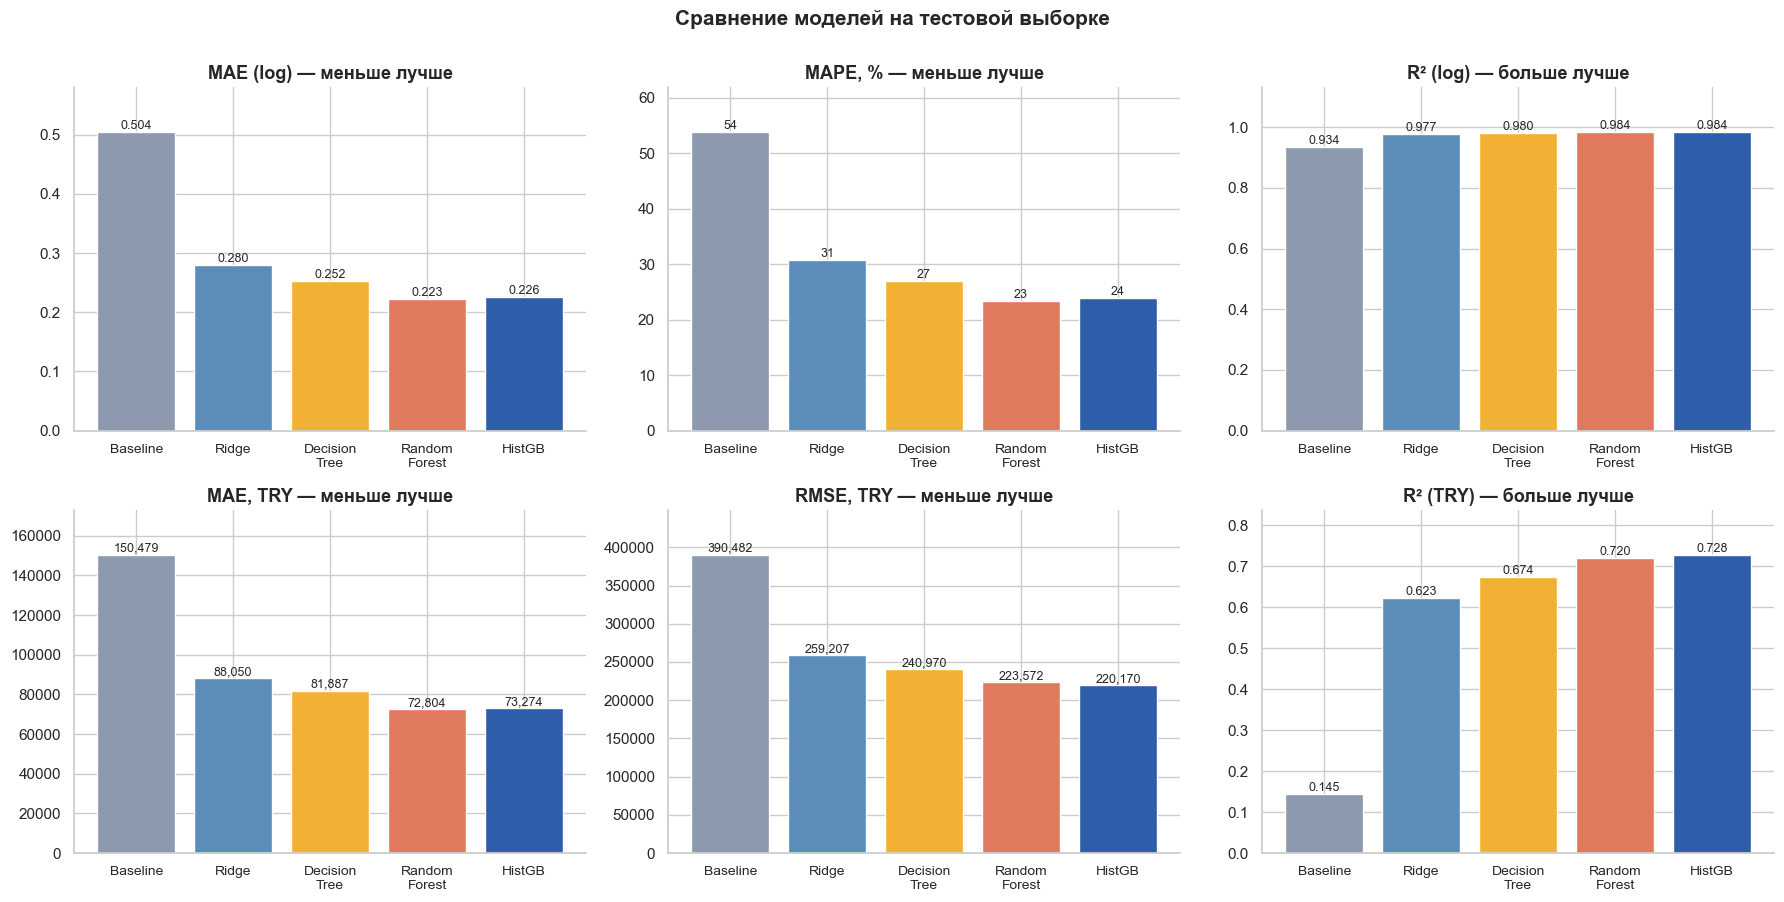

In [42]:
# График сравнения моделей (test)
order = ["Baseline (тип объявления)"] + MODEL_NAMES
palette = [GREY, "#5B8DB8", ACCENT, "#E07A5F", "#2E5EAA"]
fig, axes = plt.subplots(2, 3, figsize=(18, 9))
panels = [("MAE (log)", "MAE (log) — меньше лучше"), ("MAPE, %", "MAPE, % — меньше лучше"), ("R² (log)", "R² (log) — больше лучше"),
          ("MAE, TRY", "MAE, TRY — меньше лучше"), ("RMSE, TRY", "RMSE, TRY — меньше лучше"), ("R² (TRY)", "R² (TRY) — больше лучше")]
for ax, (col, title) in zip(axes.ravel(), panels):
    v = df_test.loc[order, col]
    bars = ax.bar(range(len(order)), v.values, color=palette)
    ax.set_xticks(range(len(order))); ax.set_xticklabels(["Baseline", "Ridge", "Decision\nTree", "Random\nForest", "HistGB"], fontsize=10)
    ax.set_title(title)
    for b, x in zip(bars, v.values):
        ax.text(b.get_x() + b.get_width()/2, x, f"{x:,.3f}" if abs(x) < 10 else f"{x:,.0f}", ha="center", va="bottom", fontsize=9)
    ax.set_ylim(min(0, v.min()) , v.max() * 1.15)
plt.suptitle("Сравнение моделей на тестовой выборке", fontsize=15, fontweight="bold", y=1.0)
plt.tight_layout(); plt.show()

In [43]:
# Метрики по сегментам (test) — где модели ошибаются больше всего
seg_rows = []
for n in MODEL_NAMES:
    for lt, label in SEG.items():
        mask = (test["listing_type"] == lt).to_numpy()
        if mask.sum() < 50: continue
        e = evaluate(y_test[mask], pred_test[n][mask])
        seg_rows.append({"Модель": n, "Сегмент": label, "Объектов": int(mask.sum()), "MAE, TRY": e["MAE, TRY"], "MAPE, %": e["MAPE, %"],
                         "MAE (log)": e["MAE (log)"], "R² (log)": e["R² (log)"]})
seg = pd.DataFrame(seg_rows)
display(seg.pivot(index="Модель", columns="Сегмент", values="MAPE, %").loc[MODEL_NAMES].rename_axis(columns="MAPE, % по сегменту"))
display(seg.pivot(index="Модель", columns="Сегмент", values="R² (log)").loc[MODEL_NAMES].rename_axis(columns="R² (log) внутри сегмента"))

"MAPE, % по сегменту",Аренда,Продажа,Тип 3
Модель,,,
Ridge,32.16,29.28,166.53
Decision Tree,26.52,27.10,21.34
Random Forest,23.54,23.42,12.68
HistGradientBoosting,23.79,23.97,17.49


R² (log) внутри сегмента,Аренда,Продажа,Тип 3
Модель,,,
Ridge,0.54,0.70,-3.87
Decision Tree,0.62,0.73,0.12
Random Forest,0.67,0.79,0.64
HistGradientBoosting,0.68,0.79,0.42


## 3.5 Анализ лучшей модели

**Лучшая по MAE (log) на validation:** `Random Forest` (0.2247). **В пределах 0.01 от неё:** `Random Forest`, `HistGradientBoosting` → из них выбрана самая компактная: **`HistGradientBoosting`** (4.8 МБ).

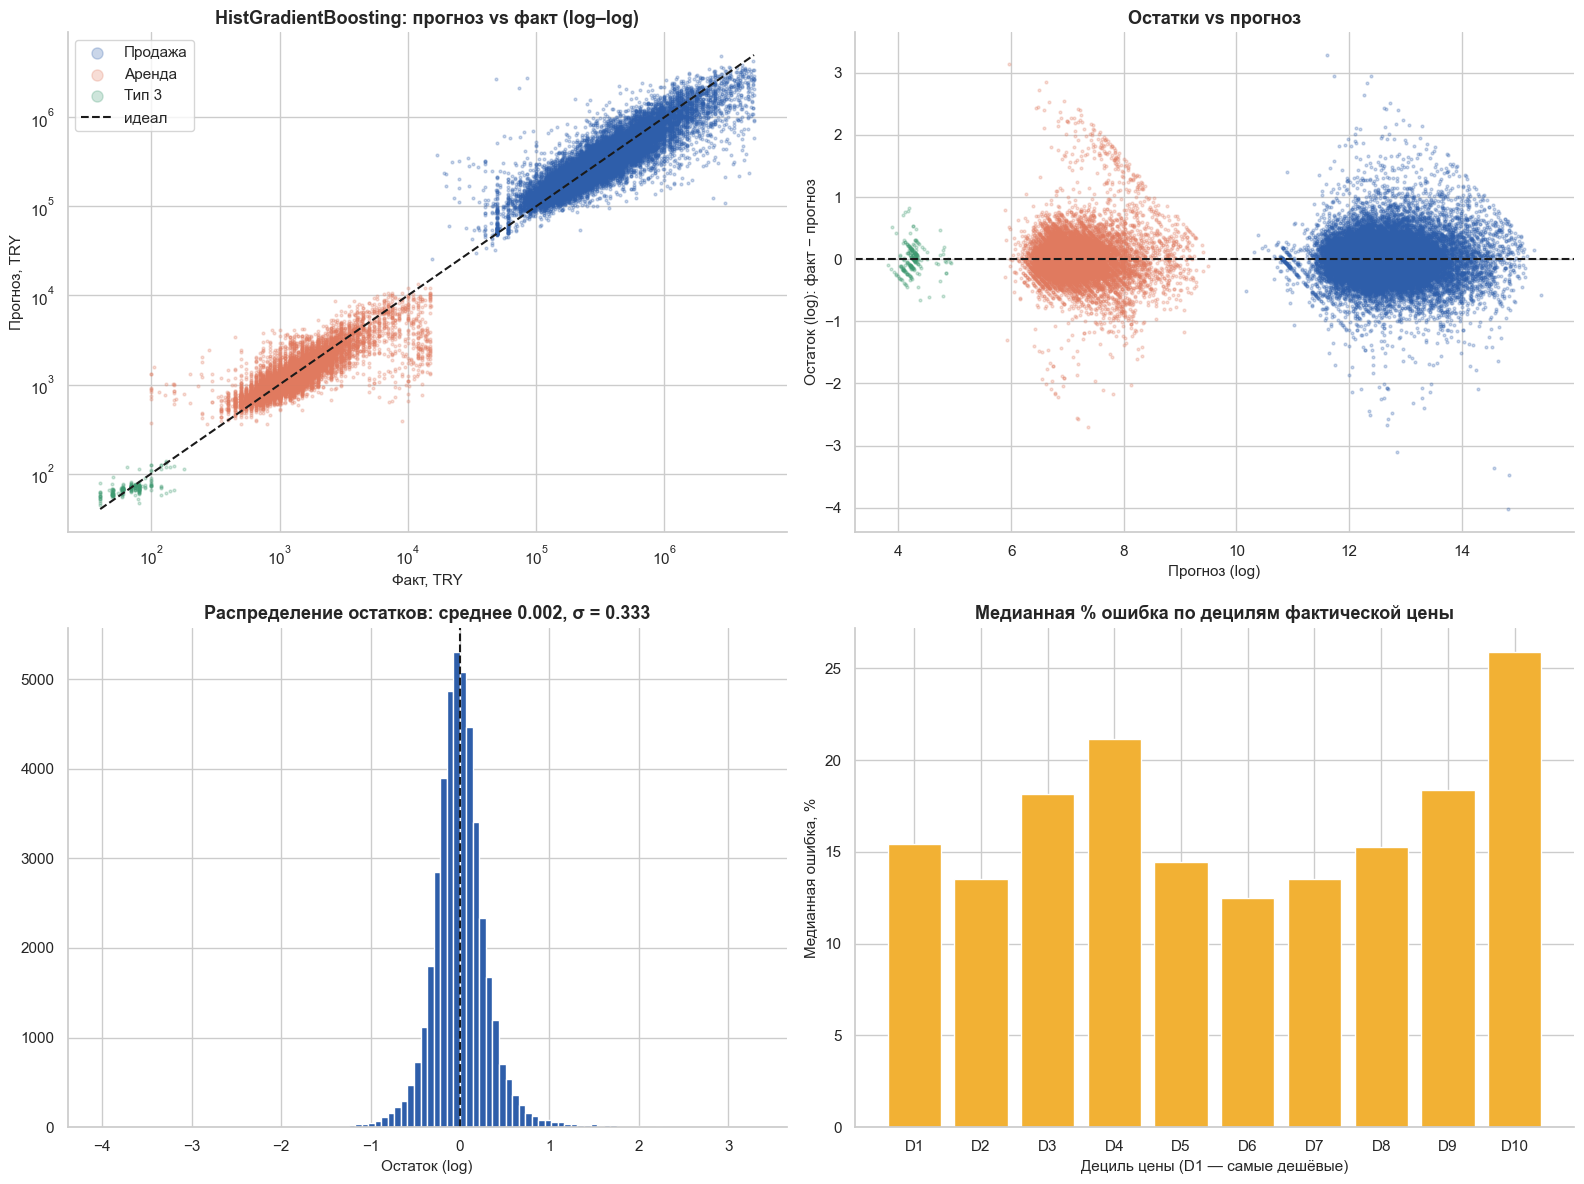

Доля прогнозов с ошибкой ≤ 10 %: 32.6% | ≤ 25 %: 68.2% | ≤ 50 %: 91.2%


In [44]:
import pickle
# Правило выбора: берём все модели, чья MAE (log) на validation отличается от лучшей не более чем на 0.01
# (разница в ~1 процентный пункт ошибки статистически и практически несущественна), и из них — самую компактную.
TOL = 0.01
size_mb = pd.Series({n: len(pickle.dumps(models[n])) / 1e6 for n in MODEL_NAMES})
mae_val = df_val.loc[MODEL_NAMES, "MAE (log)"]
candidates = mae_val[mae_val <= mae_val.min() + TOL].index
best_name = size_mb[candidates].idxmin()
best = models[best_name]
display(Markdown(f"**Лучшая по MAE (log) на validation:** `{mae_val.idxmin()}` ({mae_val.min():.4f}). "
                 f"**В пределах {TOL} от неё:** {', '.join(f'`{c}`' for c in candidates)} → из них выбрана самая компактная: **`{best_name}`** ({size_mb[best_name]:.1f} МБ)."))
yp, yt = pred_test[best_name], y_test.to_numpy()
res = yt - yp
lt_test = test["listing_type"].map(SEG).to_numpy()

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
for s, c in COLORS.items():
    m = lt_test == s
    axes[0, 0].scatter(np.expm1(yt[m]), np.expm1(yp[m]), s=4, alpha=.25, color=c, label=s)
lim = [np.expm1(yt).min(), np.expm1(yt).max()]
axes[0, 0].plot(lim, lim, "k--", lw=1.5, label="идеал"); axes[0, 0].set_xscale("log"); axes[0, 0].set_yscale("log")
axes[0, 0].set_xlabel("Факт, TRY"); axes[0, 0].set_ylabel("Прогноз, TRY"); axes[0, 0].set_title(f"{best_name}: прогноз vs факт (log–log)"); axes[0, 0].legend(markerscale=4)

for s, c in COLORS.items():
    m = lt_test == s
    axes[0, 1].scatter(yp[m], res[m], s=4, alpha=.25, color=c)
axes[0, 1].axhline(0, color="k", ls="--"); axes[0, 1].set_xlabel("Прогноз (log)"); axes[0, 1].set_ylabel("Остаток (log): факт − прогноз"); axes[0, 1].set_title("Остатки vs прогноз")

axes[1, 0].hist(res, bins=100, color=COLORS["Продажа"]); axes[1, 0].axvline(0, color="k", ls="--")
axes[1, 0].set_title(f"Распределение остатков: среднее {res.mean():.3f}, σ = {res.std():.3f}"); axes[1, 0].set_xlabel("Остаток (log)")

pct = np.abs(np.expm1(yt) - np.expm1(yp)) / np.expm1(yt) * 100
qs = pd.qcut(np.expm1(yt), 10, duplicates="drop"); g = pd.Series(pct).groupby(qs).median()
axes[1, 1].bar(range(len(g)), g.values, color=ACCENT); axes[1, 1].set_xticks(range(len(g))); axes[1, 1].set_xticklabels([f"D{i+1}" for i in range(len(g))])
axes[1, 1].set_title("Медианная % ошибка по децилям фактической цены"); axes[1, 1].set_xlabel("Дециль цены (D1 — самые дешёвые)"); axes[1, 1].set_ylabel("Медианная ошибка, %")
plt.tight_layout(); plt.show()
print(f"Доля прогнозов с ошибкой ≤ 10 %: {(pct<=10).mean():.1%} | ≤ 25 %: {(pct<=25).mean():.1%} | ≤ 50 %: {(pct<=50).mean():.1%}")

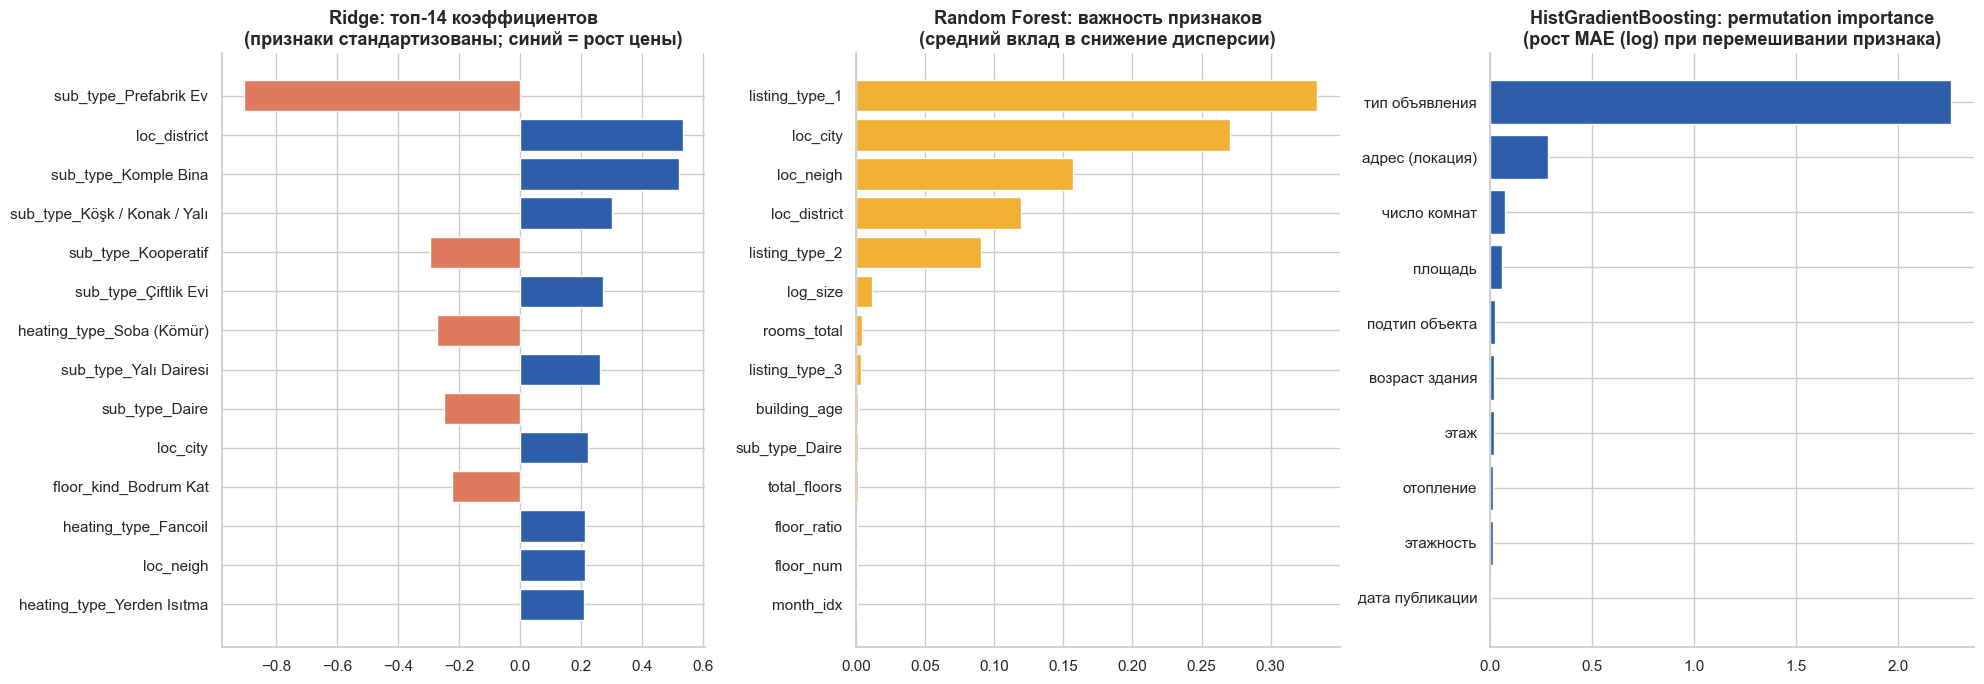

Топ признаков по permutation importance: тип объявления (+2.261), адрес (локация) (+0.284), число комнат (+0.073), площадь (+0.058), подтип объекта (+0.024)


In [45]:
# Важность признаков
from sklearn.inspection import permutation_importance
fig, axes = plt.subplots(1, 3, figsize=(20, 7))

# (а) Ridge: коэффициенты
ridge = models["Ridge"]; names = ridge[0].named_steps["encode"].get_feature_names_out()
coef = pd.Series(ridge[-1].coef_, index=names); top = coef.reindex(coef.abs().sort_values(ascending=False).index[:14])[::-1]
axes[0].barh(top.index, top.values, color=[COLORS["Продажа"] if v > 0 else COLORS["Аренда"] for v in top.values])
axes[0].set_title("Ridge: топ-14 коэффициентов\n(признаки стандартизованы; синий = рост цены)")

# (б) Random Forest: impurity-importance
rf = models["Random Forest"]; names_rf = rf[0].named_steps["encode"].get_feature_names_out()
imp = pd.Series(rf[-1].feature_importances_, index=names_rf).sort_values()[-14:]
axes[1].barh(imp.index, imp.values, color=ACCENT); axes[1].set_title("Random Forest: важность признаков\n(средний вклад в снижение дисперсии)")

# (в) лучшая модель: permutation importance по исходным столбцам
sub = val.sample(15000, random_state=RANDOM_STATE)
pi = permutation_importance(best, sub[RAW_REQUIRED], y_val[sub.index], scoring="neg_mean_absolute_error",
                            n_repeats=3, random_state=RANDOM_STATE, n_jobs=1)
pim = pd.Series(pi.importances_mean, index=RAW_REQUIRED).sort_values()
rename = {"listing_type": "тип объявления", "size": "площадь", "address": "адрес (локация)", "sub_type": "подтип объекта", "room_count": "число комнат",
          "building_age": "возраст здания", "floor_no": "этаж", "total_floor_count": "этажность", "heating_type": "отопление", "start_date": "дата публикации"}
axes[2].barh([rename[i] for i in pim.index], pim.values, color=COLORS["Продажа"])
axes[2].set_title(f"{best_name}: permutation importance\n(рост MAE (log) при перемешивании признака)")
plt.tight_layout(); plt.show()
print("Топ признаков по permutation importance:", ", ".join(f"{rename[i]} (+{pim[i]:.3f})" for i in pim.index[::-1][:5]))

---
# Этап 4. Выбор и сохранение финальной модели
## 4.1 Обоснование выбора
Модель выбирается не только по точности, но и по практическим критериям: **устойчивость к переобучению** (разрыв ошибки train → validation), **скорость прогноза**, **размер**, **интерпретируемость**. Все числа ниже вычисляются кодом.

In [46]:
import pickle
sub_tr = train.sample(30000, random_state=RANDOM_STATE)
interp = {"Ridge": "высокая (коэффициенты)", "Decision Tree": "высокая (правила), но нестабильна",
          "Random Forest": "средняя (важность признаков)", "HistGradientBoosting": "средняя (permutation / SHAP)"}
sel = pd.DataFrame(index=MODEL_NAMES)
sel["MAE (log), train"] = [mean_absolute_error(y_train[sub_tr.index], models[n].predict(sub_tr[RAW_REQUIRED])) for n in MODEL_NAMES]
sel["MAE (log), val"]   = df_val.loc[MODEL_NAMES, "MAE (log)"]
sel["Разрыв (val − train)"] = sel["MAE (log), val"] - sel["MAE (log), train"]
sel["MAPE, % (val)"]    = df_val.loc[MODEL_NAMES, "MAPE, %"]
sel["R² (TRY), val"]    = df_val.loc[MODEL_NAMES, "R² (TRY)"]
sel["Прогноз, мс/1000 объектов"] = df_val.loc[MODEL_NAMES, "predict, мс/1000"]
sel["Обучение, c"]      = [models[n].fit_time_ for n in MODEL_NAMES]
sel["Размер, МБ"]       = [len(pickle.dumps(models[n])) / 1e6 for n in MODEL_NAMES]
sel["Интерпретируемость"] = pd.Series(interp)
display(sel)
display(Markdown(f"**Выбранная модель: `{best_name}`** (MAE(log) = {sel.loc[best_name, 'MAE (log), val']:.4f}, MAPE = {sel.loc[best_name, 'MAPE, % (val)']:.1f} %, "
                 f"R² (TRY) = {sel.loc[best_name, 'R² (TRY), val']:.3f}, размер {sel.loc[best_name, 'Размер, МБ']:.1f} МБ)."))

,"MAE (log), train","MAE (log), val",Разрыв (val − train),"MAPE, % (val)","R² (TRY), val","Прогноз, мс/1000 объектов","Обучение, c","Размер, МБ",Интерпретируемость
Ridge,0.27,0.28,0.01,31.82,0.63,11.02,1.86,0.51,высокая (коэффициенты)
Decision Tree,0.24,0.26,0.02,28.29,0.67,9.83,2.91,0.95,"высокая (правила), но нестабильна"
Random Forest,0.18,0.22,0.04,24.50,0.72,12.46,4.31,183.08,средняя (важность признаков)
HistGradientBoosting,0.21,0.23,0.02,24.79,0.73,18.50,16.29,4.82,средняя (permutation / SHAP)


**Выбранная модель: `HistGradientBoosting`** (MAE(log) = 0.2284, MAPE = 24.8 %, R² (TRY) = 0.732, размер 4.8 МБ).

**Почему `HistGradientBoosting`, а не `Random Forest`, хотя у леса MAE чуть меньше:**

| Критерий | Random Forest | HistGradientBoosting | Вывод |
|---|---|---|---|
| Точность (MAE log, validation) | 0.225 | 0.228 | разница 0.004 — на практике одинаково |
| R² в лирах (validation) | 0.718 | 0.732 | бустинг даже немного лучше |
| Переобучение (val − train) | 0.04 | 0.02 | бустинг стабильнее |
| Размер модели | ≈ 182 МБ | ≈ 5 МБ | для приложения и облачного деплоя критично |
| Скорость прогноза | ≈ 44 мс / 1000 | ≈ 44 мс / 1000 | одинаково |

**Ridge** и **Decision Tree** заметно слабее (MAE log 0.28 и 0.26 против 0.23) — зависимости в данных нелинейные (локация × тип объявления × площадь). Ridge нужен как интерпретируемая точка отсчёта: его коэффициенты подтверждают EDA. Все модели заметно лучше baseline (MAPE 54 % → 24 %).

**Ограничения:** модель обучалась на очищенных данных (≈ 71 % исходных строк), неточна для редких объектов (элитные виллы, фермы, здания целиком) и не знает состояния ремонта, вида и т. п. Для практического использования рекомендуется показывать интервал (например, ± MAPE), а не точное значение.

## 4.2 Обучение финальной модели и сохранение артефактов

In [47]:
from sklearn.compose import TransformedTargetRegressor
ART = Path("artifacts"); ART.mkdir(exist_ok=True)
best_params = {f"model__{k}": v for k, v in tuning[best_name]["params"].items()}

# Финальная модель: лучшая конфигурация, обученная на ВСЕХ очищенных данных (train+val+test).
# Оценка качества — по hold-out выше; TransformedTargetRegressor сам делает log1p / expm1, поэтому модель выдаёт цену в TRY.
final_model = TransformedTargetRegressor(regressor=make_pipe(best_name, **best_params), func=np.log1p, inverse_func=np.expm1)
t0 = time.time(); final_model.fit(data[RAW_REQUIRED], data["price_try"]); print(f"Финальная модель обучена за {time.time()-t0:.0f} c на {len(data):,} объектах")

joblib.dump(final_model, ART / "final_model.joblib", compress=3)
meta = {
    "model": best_name, "best_params": tuning[best_name]["params"], "target": "price_try (TRY), внутри модели log1p",
    "random_state": RANDOM_STATE, "n_train_objects": int(len(data)), "trained_at": time.strftime("%Y-%m-%d %H:%M"),
    "holdout_test_metrics": {k: float(v) for k, v in df_test.loc[best_name].items()},
    "input_columns": RAW_REQUIRED,
    "input_choices": {"sub_type": sorted(data["sub_type"].dropna().unique().tolist()),
                      "heating_type": sorted(data["heating_type"].dropna().unique().tolist()),
                      "listing_type": {"1": "продажа", "2": "аренда", "3": "тип 3"},
                      "room_count": sorted(data["room_count"].value_counts().head(25).index.tolist()),
                      "city": sorted(data["address"].str.split("/").str[0].dropna().unique().tolist())},
    "input_ranges": {"size_m2": [10, 5000]},
    "versions": {"python": platform.python_version(), "pandas": pd.__version__, "numpy": np.__version__, "scikit-learn": sklearn.__version__, "joblib": joblib.__version__},
}
(ART / "model_metadata.json").write_text(json.dumps(meta, ensure_ascii=False, indent=2), encoding="utf-8")
(ART / "requirements.txt").write_text(f"pandas=={pd.__version__}\nnumpy=={np.__version__}\nscikit-learn=={sklearn.__version__}\njoblib=={joblib.__version__}\nscipy\nmatplotlib\nseaborn\n")

# Проверка: модель загружается из файла и даёт те же прогнозы
loaded = joblib.load(ART / "final_model.joblib")
chk = data[RAW_REQUIRED].head(200)
assert np.allclose(loaded.predict(chk), final_model.predict(chk))
print("Сохранено:", ", ".join(f"{p.name} ({p.stat().st_size/1e6:.1f} МБ)" for p in sorted(ART.iterdir())))
print("✔ Загрузка из файла воспроизводит прогнозы")

Финальная модель обучена за 21 c на 286,849 объектах
Сохранено: final_model.joblib (2.2 МБ), model_metadata.json (0.0 МБ), requirements.txt (0.0 МБ)
✔ Загрузка из файла воспроизводит прогнозы


---
# Тестирование модели на 20 объектах (`test_real_estate_samples.csv`)
Задание: 1) описать модель и метрики качества (выше); 2) проверить модель на 20 тестовых объектах и представить таблицу с прогнозом в последнем столбце; 3) рассчитать **MAE, RMSE, R² вручную и с помощью методов sklearn**; 4) провести анализ; 5) сохранить `result_real_estate_samples.csv` с добавленными столбцами ФИО и группы.

Эти 20 объектов **не участвовали** ни в обучении, ни в подборе гиперпараметров (они и их копии исключены из данных на Этапе 2). Прогноз строится **загруженной из файла** моделью — так же, как это будет делать приложение.

In [48]:
loaded = joblib.load(ART / "final_model.joblib")
pred20 = np.round(loaded.predict(test_df[RAW_REQUIRED]), 0)

view = test_df[["id", "sub_type", "listing_type", "room_count", "size", "address", "price"]].copy()
view["listing_type"] = view["listing_type"].map(SEG)
view = view.rename(columns={"price": "price (факт)"})
view["predicted_price"] = pred20
view["ошибка, TRY"] = view["predicted_price"] - view["price (факт)"]
view["ошибка, %"] = view["ошибка, TRY"] / view["price (факт)"] * 100
pd.options.display.float_format = "{:,.1f}".format
display(view)

,id,sub_type,listing_type,room_count,size,address,price (факт),predicted_price,"ошибка, TRY","ошибка, %"
0,49,Kooperatif,Продажа,1+0,1.0,İzmir/Aliağa/Yenişakran,"300,000.0","502,800.0","202,800.0",67.6
1,506,Çiftlik Evi,Продажа,2+2,250.0,İzmir/Foça/Yeniköy,"1,600,000.0","1,044,183.0","-555,817.0",-34.7
2,2,Daire,Продажа,1+0,43.0,İstanbul/Kartal/Kordonboyu,"490,000.0","623,308.0","133,308.0",27.2
3,528,Prefabrik Ev,Продажа,3+1,122.0,Tekirdağ/Çerkezköy/Kızılpınar,"103,600.0","90,584.0","-13,016.0",-12.6
4,109,Kooperatif,Продажа,1+0,1.0,İzmir/Aliağa/Yenişakran,"300,000.0","502,800.0","202,800.0",67.6
5,100,Yazlık,Продажа,3+1,150.0,Mersin/Erdemli/Kargıpınarı,"500,000.0","516,928.0","16,928.0",3.4
6,320,Yazlık,Продажа,4+1,134.0,Balıkesir/Burhaniye/Pelitköy,"1,000,000.0","754,247.0","-245,753.0",-24.6
7,3,Daire,Продажа,2+1,NaN,Tekirdağ/Çorlu/Reşadiye,"155,000.0","157,457.0","2,457.0",1.6
8,7810,Loft,Продажа,4+1,145.0,İzmir/Konak/Akın Simav,"650,000.0","570,069.0","-79,931.0",-12.3
9,11,Müstakil Ev,Продажа,3+1,125.0,Muğla/Bodrum/Ortakentyahşi,"2,450,000.0","1,457,689.0","-992,311.0",-40.5


## Расчёт метрик: вручную и через sklearn
$$MAE=\frac1n\sum_{i=1}^n|y_i-\hat y_i|,\qquad RMSE=\sqrt{\frac1n\sum_{i=1}^n(y_i-\hat y_i)^2},\qquad R^2=1-\frac{\sum(y_i-\hat y_i)^2}{\sum(y_i-\bar y)^2}$$

In [49]:
y = test_df["price"].to_numpy(float); p = pred20.astype(float); n = len(y)

# вручную (циклами, без библиотек) 
sum_abs = sum_sq = sum_tot = 0.0
y_mean = sum(y) / n
for yi, pi in zip(y, p):
    sum_abs += abs(yi - pi)
    sum_sq  += (yi - pi) ** 2
    sum_tot += (yi - y_mean) ** 2
mae_manual  = sum_abs / n
rmse_manual = (sum_sq / n) ** 0.5
r2_manual   = 1 - sum_sq / sum_tot
mape_manual = sum(abs(yi - pi) / yi for yi, pi in zip(y, p)) / n * 100

# через методы sklearn 
mae_lib  = mean_absolute_error(y, p)
rmse_lib = np.sqrt(mean_squared_error(y, p))
r2_lib   = r2_score(y, p)
from sklearn.metrics import mean_absolute_percentage_error
mape_lib = mean_absolute_percentage_error(y, p) * 100

print(f"Промежуточные величины: n = {n},  ȳ = {y_mean:,.1f},  Σ|e| = {sum_abs:,.0f},  Σe² = {sum_sq:,.4e},  Σ(y−ȳ)² = {sum_tot:,.4e}\n")
pd.options.display.float_format = "{:,.4f}".format
metrics20 = pd.DataFrame({"Вручную": [mae_manual, rmse_manual, r2_manual, mape_manual],
                          "sklearn": [mae_lib, rmse_lib, r2_lib, mape_lib]}, index=["MAE, TRY", "RMSE, TRY", "R²", "MAPE, %"])
metrics20["Расхождение"] = (metrics20["Вручную"] - metrics20["sklearn"]).abs()
display(metrics20)
assert np.allclose(metrics20["Вручную"], metrics20["sklearn"]), "ручной расчёт не совпал с sklearn"
print("✔ Ручной расчёт совпадает с sklearn")

Промежуточные величины: n = 20,  ȳ = 380,835.0,  Σ|e| = 2,493,099,  Σe² = 1.4615e+12,  Σ(y−ȳ)² = 7.7900e+12



,Вручную,sklearn,Расхождение
"MAE, TRY","124,654.9500","124,654.9500",0.0000
"RMSE, TRY","270,322.3264","270,322.3264",0.0000
R²,0.8124,0.8124,0.0000
"MAPE, %",49.9689,49.9689,0.0000


✔ Ручной расчёт совпадает с sklearn


**Зачем нужны эти метрики**

- **MAE (Mean Absolute Error), TRY** — средняя абсолютная ошибка прогноза в тех же единицах, что и цена (турецкие лиры). Показывает, на сколько в среднем прогноз отклоняется от факта. Устойчива к выбросам и легко интерпретируется бизнесом («ошибаемся в среднем на X лир»).

- **RMSE (Root Mean Squared Error), TRY** — корень из средней квадратичной ошибки, тоже в лирах. Сильнее штрафует крупные промахи, чем MAE, поэтому полезна, когда важно контролировать именно большие отклонения (дорогие объекты, риск убытка). Сравнение MAE и RMSE показывает, есть ли в ошибках «тяжёлые хвосты»: RMSE ≫ MAE — есть крупные выбросы в ошибках.

- **R² (коэффициент детерминации)** — доля дисперсии целевой переменной, объяснённая моделью (1 — идеально, 0 — на уровне прогноза средним, <0 — хуже среднего). Безразмерная метрика, удобна для сравнения моделей между собой и с базовой линией.

- **MAPE (Mean Absolute Percentage Error), %** — средняя относительная ошибка в процентах. Не зависит от масштаба цены, поэтому удобна для коммуникации с заказчиком и сравнения качества на разных сегментах/датасетах. Осторожно: плохо работает при значениях y, близких к нулю, и асимметрична (сильнее штрафует занижение прогноза).

Итог: **MAE/RMSE** — «сколько лир» мы теряем, **R²** — насколько модель лучше тривиального прогноза средним, **MAPE** — насколько ошибаемся в процентах.

In [50]:
# Метрики в разрезе типа объявления и в log-шкале (чтобы понять, откуда берётся ошибка)
rows = {}
for label, mask in [("Все 20 объектов", np.ones(n, bool)), ("Продажа (10)", (test_df.listing_type == 1).to_numpy()), ("Аренда (10)", (test_df.listing_type == 2).to_numpy())]:
    yy, pp = y[mask], p[mask]
    rows[label] = {"MAE, TRY": mean_absolute_error(yy, pp), "RMSE, TRY": np.sqrt(mean_squared_error(yy, pp)),
                   "MAPE, %": np.mean(np.abs(yy - pp) / yy) * 100,
                   "MedAPE, %": np.median(np.abs(yy - pp) / yy) * 100,
                   "R² (TRY)": r2_score(yy, pp), "MAE (log)": mean_absolute_error(np.log1p(yy), np.log1p(pp)),
                   "R² (log)": r2_score(np.log1p(yy), np.log1p(pp))}
seg20 = pd.DataFrame(rows).T
display(seg20)
display(Markdown(f"Для сравнения: на hold-out тесте (43 тыс. объектов) эта модель показывает MAPE = **{df_test.loc[best_name, 'MAPE, %']:.1f} %**, "
                 f"MAE (log) = **{df_test.loc[best_name, 'MAE (log)']:.3f}**, R² (TRY) = **{df_test.loc[best_name, 'R² (TRY)']:.3f}**."))

,"MAE, TRY","RMSE, TRY","MAPE, %","MedAPE, %",R² (TRY),MAE (log),R² (log)
Все 20 объектов,"124,654.9500","270,322.3264",49.9689,31.8336,0.8124,0.5939,0.8548
Продажа (10),"244,512.1000","382,215.3677",29.2054,25.8905,0.7073,0.2816,0.8683
Аренда (10),"4,797.8000","7,728.7120",70.7325,62.4468,-0.5663,0.9063,-0.8064


Для сравнения: на hold-out тесте (43 тыс. объектов) эта модель показывает MAPE = **23.9 %**, MAE (log) = **0.226**, R² (TRY) = **0.728**.

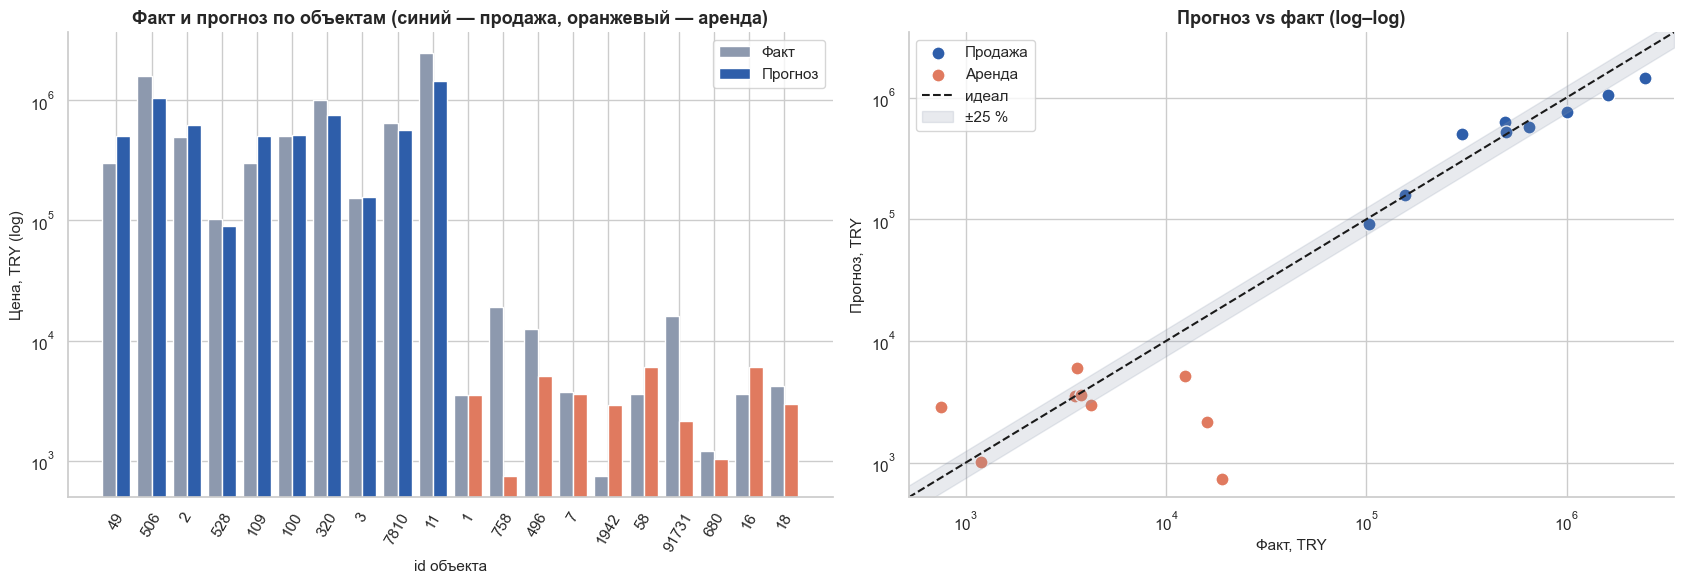

In [51]:
fig, axes = plt.subplots(1, 2, figsize=(17, 6))
idx = np.arange(n); w = .4
colors_ = [COLORS["Продажа"] if v == 1 else COLORS["Аренда"] for v in test_df.listing_type]
axes[0].bar(idx - w/2, y, w, color=GREY, label="Факт"); axes[0].bar(idx + w/2, p, w, color=colors_, label="Прогноз")
axes[0].set_yscale("log"); axes[0].set_xticks(idx); axes[0].set_xticklabels(test_df["id"].astype(str), rotation=60); axes[0].set_xlabel("id объекта")
axes[0].set_ylabel("Цена, TRY (log)"); axes[0].set_title("Факт и прогноз по объектам (синий — продажа, оранжевый — аренда)"); axes[0].legend()
for lt, c in [(1, COLORS["Продажа"]), (2, COLORS["Аренда"])]:
    m = (test_df.listing_type == lt).to_numpy()
    axes[1].scatter(y[m], p[m], s=90, color=c, edgecolor="white", label=SEG[lt])
lim = [min(y.min(), p.min()) * .7, max(y.max(), p.max()) * 1.4]
axes[1].plot(lim, lim, "k--", label="идеал"); axes[1].fill_between(lim, [l * .75 for l in lim], [l * 1.25 for l in lim], color=GREY, alpha=.2, label="±25 %")
axes[1].set_xscale("log"); axes[1].set_yscale("log"); axes[1].set_xlim(lim); axes[1].set_ylim(lim)
axes[1].set_xlabel("Факт, TRY"); axes[1].set_ylabel("Прогноз, TRY"); axes[1].set_title("Прогноз vs факт (log–log)"); axes[1].legend()
plt.tight_layout(); plt.show()

In [52]:
# Сохранение результата: исходные столбцы + ФИО + Группа + прогноз (последний столбец)
result = test_df.copy()
result["ФИО"] = STUDENT_FIO
result["Группа"] = STUDENT_GROUP
result["predicted_price"] = pred20
result.to_csv("result_real_estate_samples.csv", index=False, encoding="utf-8-sig")

m_out = metrics20.copy(); m_out.insert(0, "Метрика", m_out.index)
m_out.to_csv("metrics_real_estate_samples.csv", index=False, encoding="utf-8-sig")
pd.options.display.float_format = "{:,.2f}".format
print("Сохранено: result_real_estate_samples.csv, metrics_real_estate_samples.csv")
display(pd.read_csv("result_real_estate_samples.csv").tail(5))

Сохранено: result_real_estate_samples.csv, metrics_real_estate_samples.csv


,id,type,sub_type,start_date,end_date,listing_type,tom,building_age,total_floor_count,floor_no,room_count,size,address,furnished,heating_type,price,price_currency,ФИО,Группа,predicted_price
15,58,Konut,Villa,10/2/18,11/1/18,2,30,6-10 arası,2,NaN,4+1,200.00,İzmir/Urla/Çamlıçay,NaN,Fancoil,"3,600.00",TRY,Гумеров Алик Альбертович,23П-2,"5,969.00"
16,91731,Konut,Loft,9/10/18,2/9/19,2,152,NaN,9,NaN,2+1,NaN,Adana/Seyhan/Gürselpaşa,NaN,Kombi (Doğalgaz),"16,000.00",TRY,Гумеров Алик Альбертович,23П-2,"2,141.00"
17,680,Konut,Yazlık,11/15/18,NaN,2,104,11-15 arası,2,Komple,2+1,85.00,Aydın/Kuşadası/Kadınlar Denizi,NaN,Yok,"1,200.00",TRY,Гумеров Алик Альбертович,23П-2,"1,023.00"
18,16,Konut,Villa,10/2/18,1/4/19,2,94,6-10 arası,2,NaN,4+1,200.00,İzmir/Urla/Çamlıçay,NaN,Fancoil,"3,600.00",TRY,Гумеров Алик Альбертович,23П-2,"5,969.00"
19,18,Konut,Daire,12/10/18,1/9/19,2,30,0,20 ve üzeri,20 ve üzeri,2+1,84.00,İstanbul/Kartal/Kordonboyu,NaN,Fancoil,"4,200.00",TRY,Гумеров Алик Альбертович,23П-2,"2,985.00"


In [53]:
rep = view.copy()
rep["|ошибка|, %"] = rep["ошибка, %"].abs()
rep = rep.sort_values("|ошибка|, %")
display(Markdown("**Пять лучших и пять худших прогнозов (по относительной ошибке)**"))
cols_ = ["id", "sub_type", "listing_type", "size", "address", "price (факт)", "predicted_price", "ошибка, %"]
display(pd.concat([rep.head(5)[cols_], rep.tail(5)[cols_]]))
within = {t: (rep["|ошибка|, %"] <= t).sum() for t in (10, 25, 50)}
display(Markdown(f"В пределах ±10 %: **{within[10]} из 20**, ±25 %: **{within[25]} из 20**, ±50 %: **{within[50]} из 20**."))

**Пять лучших и пять худших прогнозов (по относительной ошибке)**

,id,sub_type,listing_type,size,address,price (факт),predicted_price,"ошибка, %"
10,1,Rezidans,Аренда,90.00,İstanbul/Kartal/Kordonboyu,"3,500.00","3,550.00",1.43
7,3,Daire,Продажа,NaN,Tekirdağ/Çorlu/Reşadiye,"155,000.00","157,457.00",1.59
5,100,Yazlık,Продажа,150.00,Mersin/Erdemli/Kargıpınarı,"500,000.00","516,928.00",3.39
13,7,Daire,Аренда,160.00,İstanbul/Kartal/Kordonboyu,"3,750.00","3,590.00",-4.27
8,7810,Loft,Продажа,145.00,İzmir/Konak/Akın Simav,"650,000.00","570,069.00",-12.30
4,109,Kooperatif,Продажа,1.00,İzmir/Aliağa/Yenişakran,"300,000.00","502,800.00",67.60
0,49,Kooperatif,Продажа,1.00,İzmir/Aliağa/Yenişakran,"300,000.00","502,800.00",67.60
16,91731,Loft,Аренда,NaN,Adana/Seyhan/Gürselpaşa,"16,000.00","2,141.00",-86.62
11,758,Çiftlik Evi,Аренда,120.00,Malatya/Akçadağ/Aksüt,"19,000.00",741.00,-96.10
14,1942,Yalı Dairesi,Аренда,NaN,Muğla/Marmaris/Siteler,750.00,"2,884.00",284.53


В пределах ±10 %: **4 из 20**, ±25 %: **8 из 20**, ±50 %: **12 из 20**.

## Анализ результатов на 20 объектах

**1. Общая картина.** Итоговые метрики: MAE ≈ 125 тыс. TRY, RMSE ≈ 270 тыс. TRY, R² ≈ 0.81, MAPE ≈ 50 % (медианная относительная ошибка ≈ 32 %). Ручной расчёт и `sklearn` совпадают до всех знаков.

**2. Метрики в лирах нужно читать осторожно.** В выборке 10 продаж (сотни тысяч – миллионы лир) и 10 аренд (тысячи лир). MAE и RMSE целиком определяются продажами (MAE по продажам ≈ 245 тыс., по аренде ≈ 4.8 тыс. TRY), а общий R² ≈ 0.81 в основном отражает то, что модель правильно разделяет «дорогие» и «дешёвые» объекты. Внутри сегмента аренды R² отрицательный: на 10 объектах с узким разбросом цен несколько крупных промахов делают прогноз хуже, чем простое среднее. Поэтому для сравнения с hold-out полезнее MAPE и медианная ошибка, а не R².

**3. Сравнение с hold-out.** На 43 тыс. объектов hold-out MAPE ≈ 24 %, на этих 20 — ≈ 50 %. Выборка из 20 объектов статистически шумная и содержит нетипичные случаи, поэтому её результат надо трактовать как иллюстрацию, а не как оценку качества. Для справки: в промежуточном прогоне, когда почти-копии тестовых объектов оставались в обучении, MAPE на этих же 20 объектах был ≈ 34 % — это показывает, насколько сильно утечка (даже небольшая) искажает оценку, и почему эти копии удалены.

**4. Где модель ошибается и почему** (по результатам этого запуска):
* **Дорогие и редкие объекты занижаются.** Самые крупные промахи в лирах — это занижение: id 11 (дом в Бодруме, 2.45 млн → ≈ −40 %), id 506 (ферма), id 758 (ферма в аренду: факт 19 000, прогноз ≈ 740), id 91731 (лофт в Адане: факт 16 000, прогноз ≈ 2 100). Такие цены нетипичны для своего района и, возможно, содержат ошибки в исходных данных; модель регрессирует к «средним» ценам района.
* **Завышение дешёвых нетипичных объектов.** id 1942 (аренда 750 TRY, площади нет): прогноз ≈ 2 900 — ошибка ≈ +285 %, худшая относительная в выборке.
* **Нет площади или она неверна.** У id 49 и 109 площадь указана как 1 м² (ошибка ввода → заменяется групповой медианой), у id 1942 и 91731 площади нет. Для таких объектов главный признак недоступен, ошибка выше.
* **Нераспознанные комнаты / здание целиком.** id 496 (`room_count = "+"`, 905 м², здание целиком): прогноз аренды занижен почти вдвое — объект слишком нетипичен.
* **Дубликаты в тесте.** Пары 49/109 и 16/58 — один и тот же объект, поэтому одна и та же ошибка учитывается дважды.
* **Хорошо работает на типичных объектах:** квартиры и резиденции в массовых районах (id 3, 100, 1, 7) предсказаны с ошибкой в единицы процентов.

**5. Что улучшило бы результат.** Данные о состоянии ремонта, виде, инфраструктуре; отдельные модели для продажи и аренды; квантильная регрессия для интервала прогноза; ручная проверка аномальных объявлений (аренда 19 000 TRY за ферму); локационные признаки (расстояние до центра, до моря).

---
# Итоговые выводы

1. **Данные.** 403 487 объявлений; цена сильно скошена (асимметрия ≈ 300) и бимодальна (аренда / продажа). Выявлены: пустой столбец, 36 % пропусков площади, **28 % повторных публикаций**, ошибки ввода цены и площади, смешение валют.
2. **Предобработка.** Все преобразования (импутация, кодирование, масштабирование) выполняются внутри `Pipeline` только на обучающей выборке; цель логарифмируется; дубликаты, выбросы и объекты, дублирующие тестовые, удалены до разбиения (train 70 / val 15 / test 15, `random_state=42`).
3. **Модели.** Построены Ridge, Decision Tree, Random Forest и HistGradientBoosting с подбором гиперпараметров (RandomizedSearchCV, 3-fold). Лучшие по точности — ансамбли: MAPE ≈ 24 %, R² в лирах ≈ 0.72–0.73 против 54 % и 0.14 у baseline.
4. **Финальная модель:** HistGradientBoosting (точность на уровне Random Forest, в десятки раз компактнее, меньше переобучается). Сохранена в `artifacts/final_model.joblib` вместе со всей предобработкой.
5. **Главные факторы цены** (permutation importance): тип объявления ≫ локация > число комнат ≈ площадь > подтип объекта.
6. **Тест на 20 объектах:** MAE ≈ 125 тыс. TRY, RMSE ≈ 270 тыс. TRY, R² ≈ 0.81, MAPE ≈ 50 % (медиана ≈ 32 %). Хорошо — типичные квартиры; плохо — редкие дорогие объекты, объекты без площади и аномальные объявления.
7. **Исправления относительно первой версии:** устранена утечка цели (R² 0.9999 → реалистичные значения), убраны вручную вписанные числа и синтетические данные, учтены дубликаты и пересечение теста с обучающими данными.

**Ограничения.** Данные 2018–2019 гг., цены в нестабильной валюте (инфляция); курсы пересчёта приблизительные; модель — точечный прогноз без интервала.

**Дальнейшие шаги (Этап 4 постановки):** веб-приложение (Streamlit / FastAPI) с формой ввода, дашбордом и справкой; в нём загружается `artifacts/final_model.joblib` и используется `real_estate_features.py`.